# ExtraaLearn: Lead Intelligence System
## Practical Data Science | Elective Project

### Rob Shypitka

---

ExtraaLearn is an EdTech startup selling tech programs to students and working professionals. Lead volume keeps growing. Sales cannot call everyone, so the business needs a way to decide which leads should get the first touch.

This project builds a Lead Intelligence System to answer that question:

- Predict which leads are most likely to convert to paying customers
- Show what separates converters from everyone else
- Give the sales team a prioritized list of who they should contact first

The notebook walks through the project end to end: data audit, exploratory analysis, preprocessing, modeling, explainability, lead scoring, and recommendations.

## Contents

1. Business Problem Overview
2. Setup & Library Imports
3. Data Understanding & Audit
4. Exploratory Data Analysis (EDA)
5. Preprocessing & Feature Engineering
6. Modeling & Model Evaluation
7. Feature Importance & Explainability
8. Lead Scoring & Priority Tiers
9. Recommendations
10. Limitations
11. Conclusions & Executive Summary
12. Appendix: Data Dictionary

## Business Problem Overview

### Industry Context

EdTech is a crowded industry. ExtraaLearn doesn't have the brand recognition or ad budget of the big players, so how the
sales team spends its time matters more here than it would at a larger company. Misallocated effort shows up in the
conversion numbers fast.

### The Problem

Leads come in from the website, mobile app, socials, and referrals. Right now they all go into the same queue. A rep
working that queue has no real way to tell whether the lead they are contacting is a strong close or a dead end. Timing
matters and real prospects can cool off quickly if the sales reps work through low-probability contacts first.

So which leads convert, and what do they have in common?

### Objective

1. Predict who's likely to convert
2. Find the features that actually drive conversion
3. Model what a high-conversion lead looks like
4. Translate that into something sales and marketing can act on

### Approach

Supervised binary classification. Target is status (1 = converted, 0 = not converted).

| Phase | Focus |
|-------|-------|
| Data Understanding | Structure, types, completeness, class split |
| EDA | Conversion patterns by segment and behavior |
| Preprocessing | Encoding, scaling, outlier treatment, feature engineering |
| Modeling | Logistic Regression through tuned ensembles, with CV |
| Evaluation | Precision, Recall, F1, ROC-AUC, PR-AUC |
| Explainability | SHAP values, business translation |
| Lead Scoring | Probability tiers with sales actions |

Conversion rate sits around 30%, so accuracy is not the best metric here. The evaluation focuses on Recall, Precision, F1-Score, ROC-AUC, and PR-AUC, with the final output being a tiered lead list.

---

## Setup & Library Imports
Imports are grouped by function

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import warnings

# Suppress non-critical library warnings to keep notebook output focused on results
warnings.filterwarnings("ignore")

# Visualization libraries
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 150
sns.set_theme(style="whitegrid", palette="muted")

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

# Scikit-learn: models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Scikit-learn: evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

# Advanced modeling
from xgboost import XGBClassifier

# Model explainability
import shap

# Notebook display utilities
from IPython.display import display, HTML

# HTML export styling
# Keeps markdown tables left-aligned when the notebook is exported to HTML

display(HTML("""
<style>
table {
    margin-left: 0 !important;
    margin-right: auto !important;
}

th, td {
    text-align: left !important;
}
</style>
"""))

print(f"numpy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"sklearn    {__import__('sklearn').__version__}")
print(f"shap       {shap.__version__}")
print("Environment ready.")

numpy      2.4.4
pandas     3.0.1
sklearn    1.8.0
shap       0.51.0
Environment ready.


***Note:***
Imported versions above are current at the time this notebook was developed. Newer ones may exist in the future.

---

## Data Understanding & Audit

The first pass will check: shape, types, nulls, basic stats. Get an idea for what's actually in the file before doing anything with it.

In [2]:
# Read the CSV into a DataFrame
data = pd.read_csv("ExtraaLearn.csv")

print('Dataset Preview (First 5 Rows)')
display(data.head())

# Shape & Structure
# Check on dimensions and column data types
print(f'\nDataset contains {data.shape[0]} rows and {data.shape[1]} columns.')
print('\nColumn Types & Non-Null Counts')
print()
data.info()

# Confirm data completeness, missing Values
null_summary = pd.DataFrame(data.isnull().sum(), columns=['Missing Values'])
null_summary['% Missing'] = (null_summary['Missing Values'] / len(data) * 100).round(2)
print('\nMissing Value Check')
display(null_summary)

# Check for duplicates
print(f'Duplicate rows: {data.duplicated().sum()}')

# Summary Statistics
# Split numeric and categorical data, combined describe()
# tables can be more difficult to read
print('\nNumeric Features: Summary Statistics')
display(data.describe().T)

print('\nCategorical Features: Value Counts')
display(data.describe(include='object').T)


Dataset Preview (First 5 Rows)


,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.86,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.32,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.07,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.06,Website Activity,No,No,No,No,No,1
4,EXT005,23,Student,Website,High,4,600,16.91,Email Activity,No,No,No,No,No,0



Dataset contains 4612 rows and 15 columns.

Column Types & Non-Null Counts

<class 'pandas.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     4612 non-null   str    
 1   age                    4612 non-null   int64  
 2   current_occupation     4612 non-null   str    
 3   first_interaction      4612 non-null   str    
 4   profile_completed      4612 non-null   str    
 5   website_visits         4612 non-null   int64  
 6   time_spent_on_website  4612 non-null   int64  
 7   page_views_per_visit   4612 non-null   float64
 8   last_activity          4612 non-null   str    
 9   print_media_type1      4612 non-null   str    
 10  print_media_type2      4612 non-null   str    
 11  digital_media          4612 non-null   str    
 12  educational_channels   4612 non-null   str    
 13  referral               4612 non-null   str

,Missing Values,% Missing
ID,0,0.00
age,0,0.00
current_occupation,0,0.00
first_interaction,0,0.00
profile_completed,0,0.00
website_visits,0,0.00
time_spent_on_website,0,0.00
page_views_per_visit,0,0.00
last_activity,0,0.00
print_media_type1,0,0.00


Duplicate rows: 0

Numeric Features: Summary Statistics


,count,mean,std,min,25%,50%,75%,max
age,4612.00,46.20,13.16,18.00,36.00,51.00,57.00,63.00
website_visits,4612.00,3.57,2.83,0.00,2.00,3.00,5.00,30.00
time_spent_on_website,4612.00,724.01,743.83,0.00,148.75,376.00,1336.75,2537.00
page_views_per_visit,4612.00,3.03,1.97,0.00,2.08,2.79,3.76,18.43
status,4612.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00



Categorical Features: Value Counts


,count,unique,top,freq
ID,4612,4612,EXT001,1
current_occupation,4612,3,Professional,2616
first_interaction,4612,2,Website,2542
profile_completed,4612,3,High,2264
last_activity,4612,3,Email Activity,2278
print_media_type1,4612,2,No,4115
print_media_type2,4612,2,No,4379
digital_media,4612,2,No,4085
educational_channels,4612,2,No,3907
referral,4612,2,No,4519


#### Observations

The file is clean and ready for analysis.

- No null values across the 15 columns
- No duplicate rows
- Data types look appropriate: numeric fields are stored as integers/floats and categorical fields are stored as strings

A few items are worth carrying forward into preprocessing:

- `time_spent_on_website` has a mean of 724 and a median of 376, suggesting a right tail of high-engagement leads.
- `website_visits` and `page_views_per_visit` show similar patterns, with medians below their means and high maximum values.
- These engagement-related features should be reviewed for outliers before modeling.

`ID` is only a row identifier, so it will be preserved separately for later scoring but excluded from model training.

---

### Feature Type Separation

Before starting exploratory analysis, the columns are separated into numeric and categorical groups. This keeps the EDA code cleaner and ensures each feature type is analyzed with the appropriate visualization.

The target column, `status`, is excluded from the numeric feature list because it is the outcome we are trying to predict. The `ID` column is excluded from categorical analysis because it is only a unique row identifier and does not provide meaningful business insight.

In [3]:
# Separate numeric and categorical features

# Numeric features: exclude the target variable because it is the outcome
num_cols = data.select_dtypes(include=["int64", "float64"]).columns.drop("status").tolist()

# Categorical features: exclude ID because it is only a unique identifier
cat_cols = data.select_dtypes(include=["object", "string"]).columns.tolist()
cat_cols = [col for col in cat_cols if col != "ID"]

print("Numeric features:")
print(num_cols)

print("\nCategorical features:")
print(cat_cols)

Numeric features:
['age', 'website_visits', 'time_spent_on_website', 'page_views_per_visit']

Categorical features:
['current_occupation', 'first_interaction', 'profile_completed', 'last_activity', 'print_media_type1', 'print_media_type2', 'digital_media', 'educational_channels', 'referral']


## Exploratory Data Analysis (EDA)

The data is clean so the next step is to figure out what's in it.

The analysis is broken into two phases:

**Univariate**: each feature on its own. Distribution shape and spread for the numerical values, value counts for the
categorical values. Mostly setting up what needs handling later.

**Multivariate**: features against the target. This is the important part for modeling. Anything that shows a real
gap between converters and non-converters is something the model should identify.

Order of Analysis:

1. Target Distribution
2. Numeric Features
3. Categorical Features
4. Correlation Analysis - Numeric Features
5. Conversion Rates by Category
6. Numeric Features by Conversion Status

### Univariate Analysis

#### Target Distribution

Target Variable Distribution


,Count,% Share
Not Converted (0),3235,70.14
Converted (1),1377,29.86


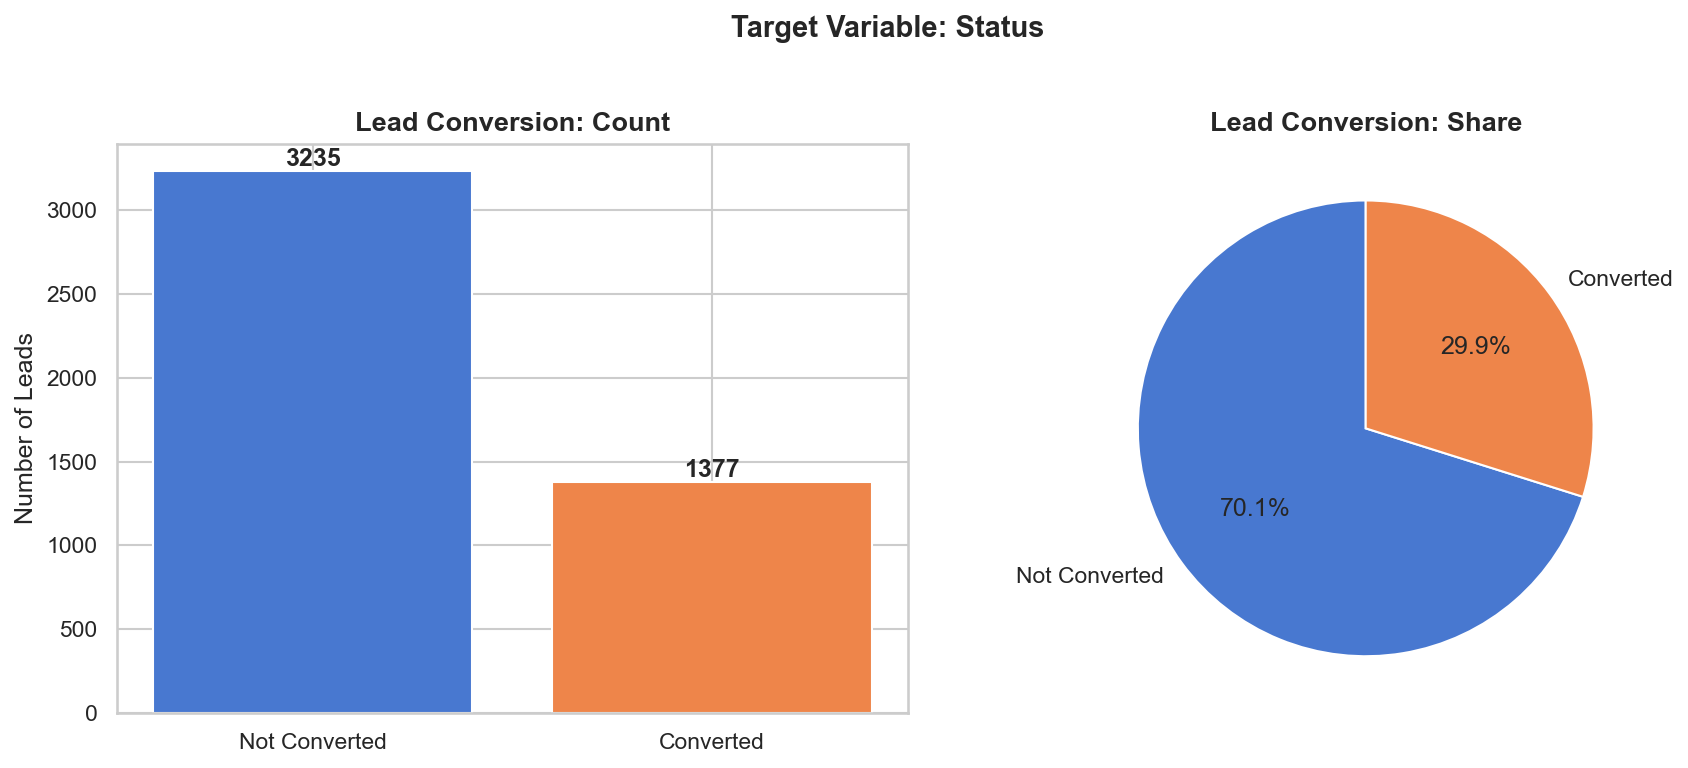

In [4]:
# Target Distribution (status)
# Understand how balanced the target variable is.
# A heavily imbalanced target means accuracy is a misleading metric. A model
# that always predicts the majority class would look accurate while catching zero real customers.

# Count and percentage breakdown of the target
target_counts = data['status'].value_counts()
target_pct = data['status'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    '% Share': target_pct.round(2)
})
target_summary.index = ['Not Converted (0)', 'Converted (1)']

print('Target Variable Distribution')
display(target_summary)

# Visualize the class split
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart, raw counts
axes[0].bar(
    ['Not Converted', 'Converted'],
    target_counts.values,
    color=sns.color_palette('muted')[0:2]
)
axes[0].set_title('Lead Conversion: Count', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Leads')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

# Pie chart, proportions
axes[1].pie(
    target_counts.values,
    labels=['Not Converted', 'Converted'],
    autopct='%1.1f%%',
    colors=sns.color_palette('muted')[0:2],
    startangle=90
)
axes[1].set_title('Lead Conversion: Share', fontsize=13, fontweight='bold')

plt.suptitle('Target Variable: Status', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

#### Observations

About 70% of leads did not convert and 30% did convert. This is a noticeable imbalance, but it is still manageable for this analysis.

For modeling, this means accuracy should not be the main decision metric. A model that predicts every lead as “not converted” would still appear roughly 70% accurate, while failing to identify any actual converters.

Because of that, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC will be more useful for evaluating model performance. Models that support it will use `class_weight='balanced'` to help account for the difference between converted and non-converted leads.

The imbalance is not extreme enough to require additional balancing techniques like SMOTE. A 70/30 split is reasonable for this project.

---

### Numeric Features

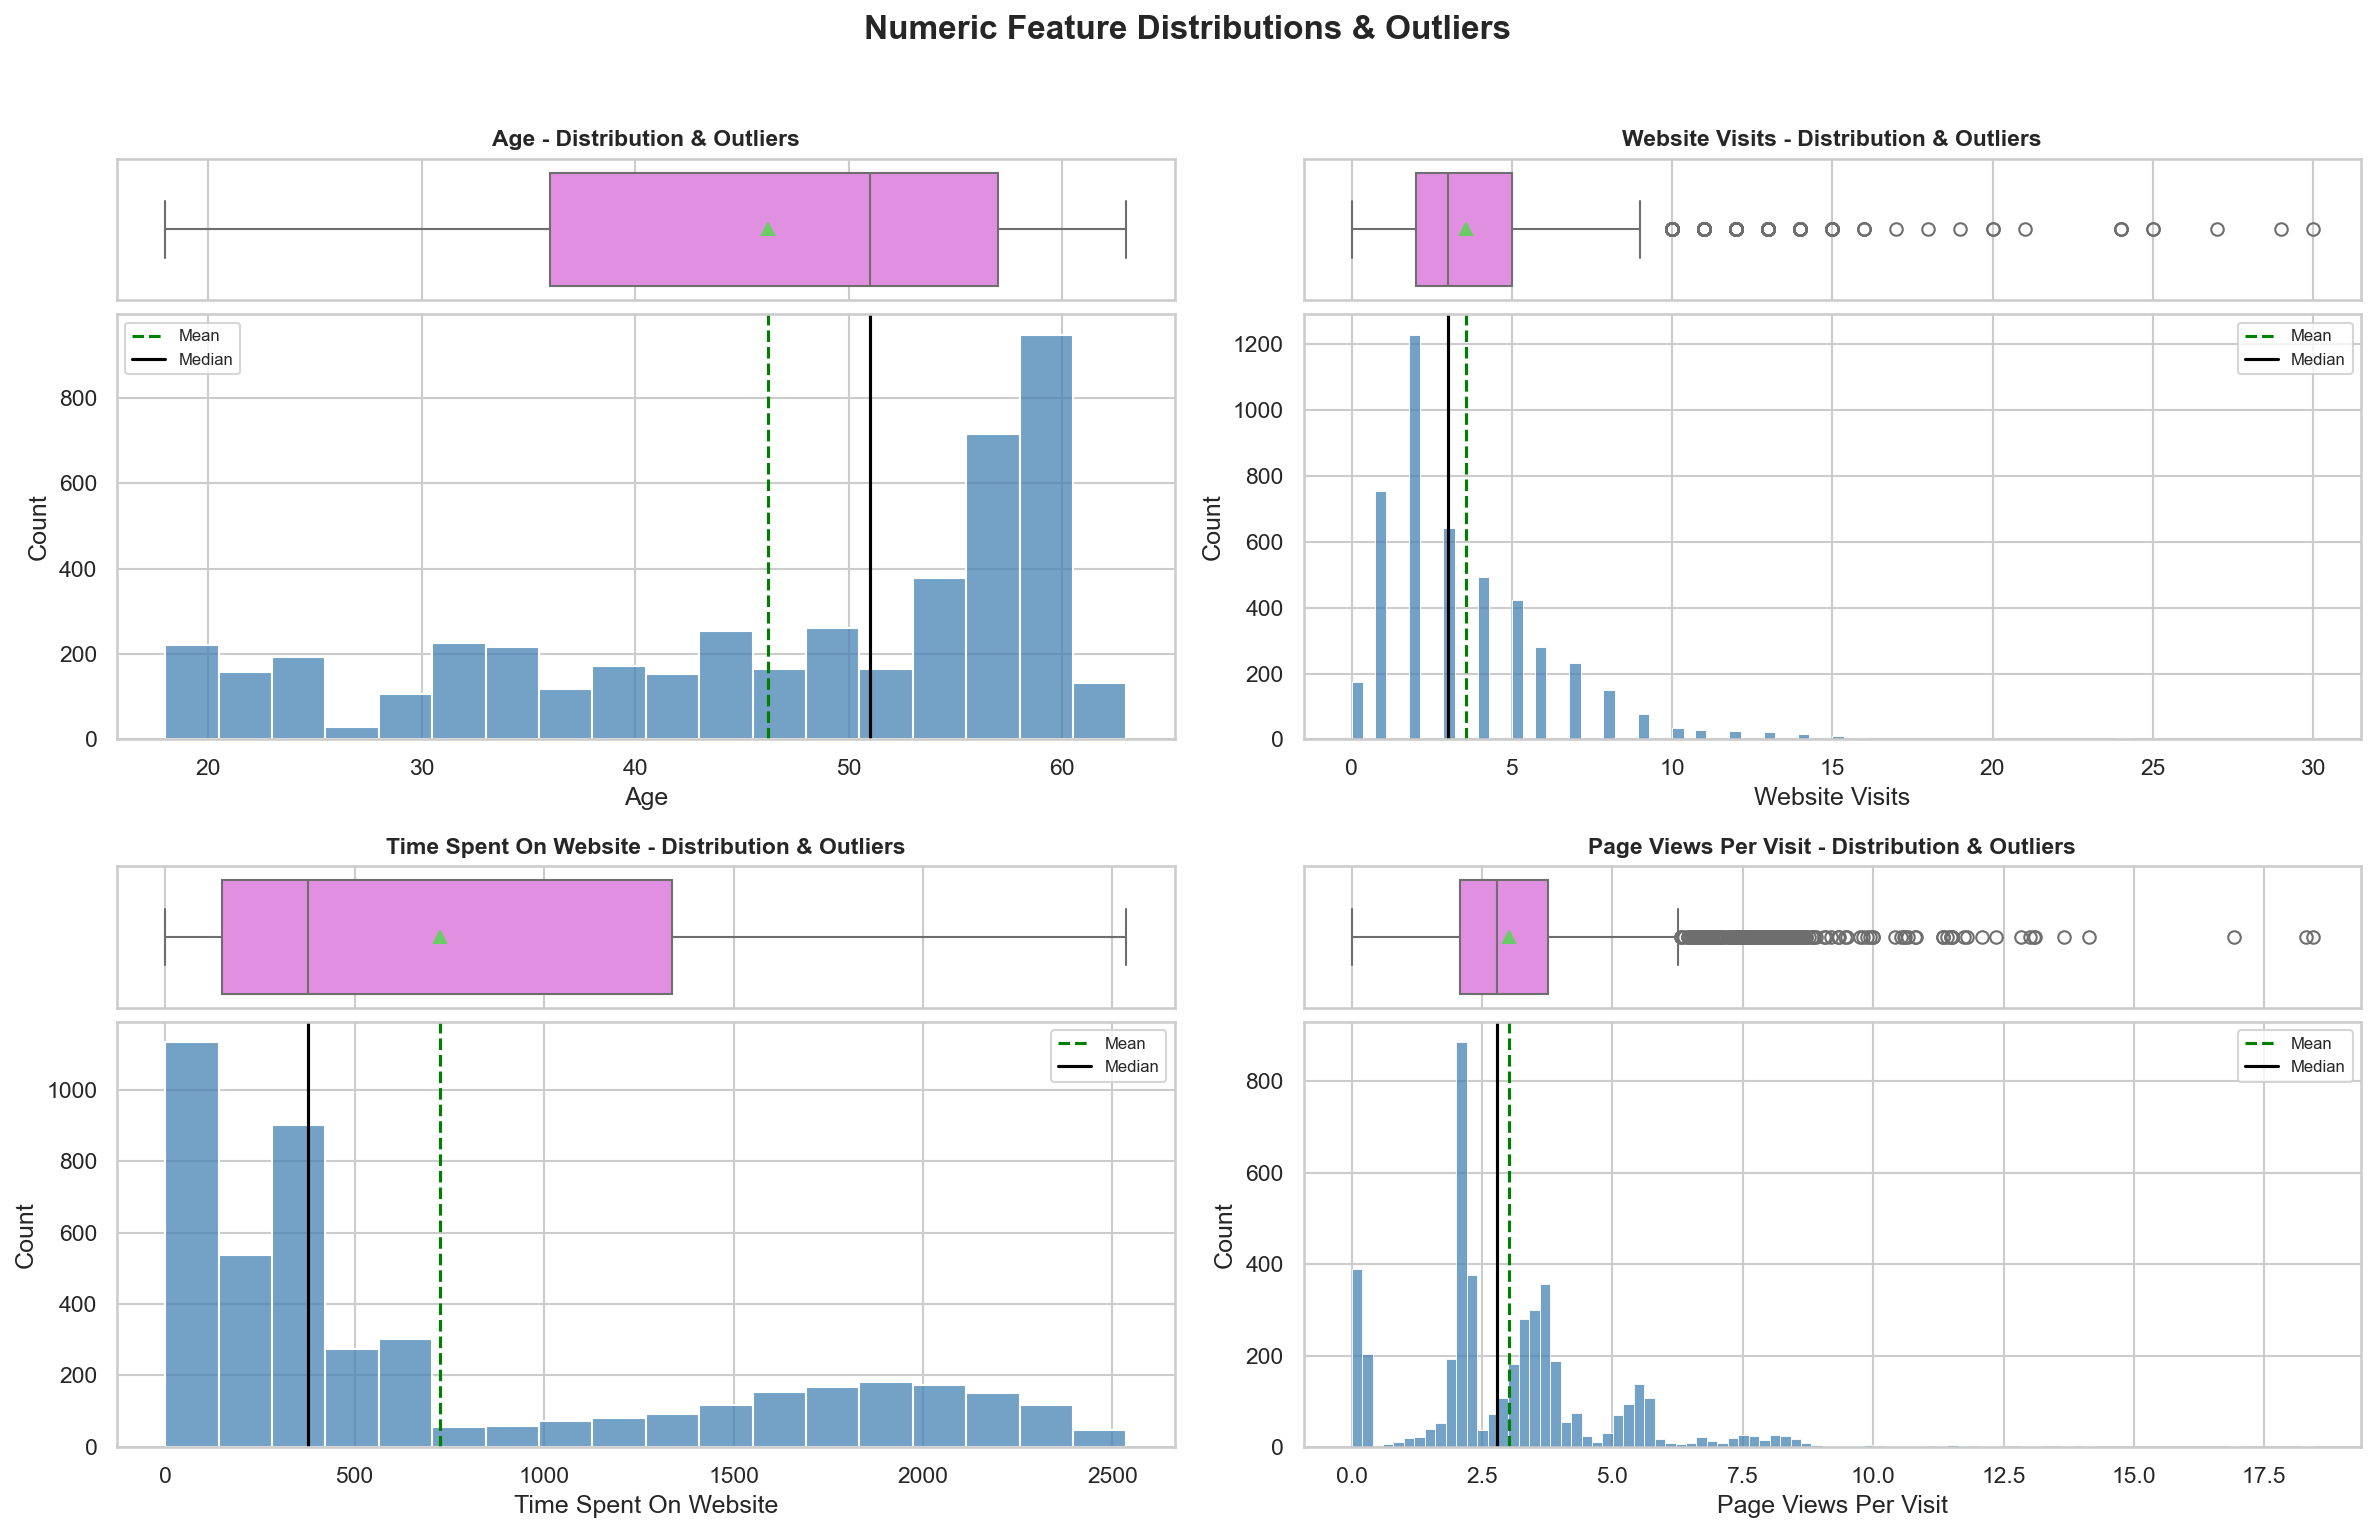

In [5]:
# Histogram & Boxplot Distributions
n_cols = 2
n_rows = 2

fig = plt.figure(figsize=(16, 10))

outer_grid = fig.add_gridspec(n_rows, n_cols)

for i, feature in enumerate(num_cols):
    
    row = i // n_cols
    col = i % n_cols
    
    inner_grid = outer_grid[row, col].subgridspec(
        2, 1,
        height_ratios=[0.25, 0.75],
        hspace=0.05
    )
    
    ax_box = fig.add_subplot(inner_grid[0])
    ax_hist = fig.add_subplot(inner_grid[1], sharex=ax_box)
    
    sns.boxplot(
        data=data,
        x=feature,
        ax=ax_box,
        showmeans=True,
        color='violet'
    )
    
    sns.histplot(
        data=data,
        x=feature,
        kde=False,
        ax=ax_hist,
        color='steelblue'
    )
    
    ax_hist.axvline(
        data[feature].mean(),
        color='green',
        linestyle='--',
        label='Mean'
    )
    
    ax_hist.axvline(
        data[feature].median(),
        color='black',
        linestyle='-',
        label='Median'
    )
    
    ax_box.set_title(
        f'{feature.replace("_", " ").title()} - Distribution & Outliers',
        fontsize=11,
        fontweight='bold'
    )
    
    ax_box.set_xlabel('')
    ax_hist.set_xlabel(feature.replace('_', ' ').title())
    
    ax_box.tick_params(axis='x', labelbottom=False)
    ax_hist.legend(fontsize=8)

fig.suptitle(
    'Numeric Feature Distributions & Outliers',
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

**Age:** Lead ages range from 18 to 63, with most leads concentrated in the middle to older adult range. The distribution leans slightly toward older leads, suggesting that ExtraaLearn is attracting many working-age adults rather than only younger students.

**Website Visits:** Most leads visit the website only a few times, while a smaller number of leads return much more frequently. This feature shows a clear right tail and visible high-end outliers, meaning some leads have unusually high visit activity compared with the typical lead.

**Time Spent on Website:** Time spent on the website varies widely across leads. Many leads spend relatively little time on the site, while a smaller group spends substantially more time. Even though the spread is wide, this feature does not show the same level of outlier concern as website visits or page views per visit.

**Page Views per Visit:** Most leads view a moderate number of pages per visit, but this feature also shows several high-end outliers. These outliers suggest that some leads browse much more deeply than the average visitor.

**Numeric Feature Takeaway:** The numeric features show meaningful differences in lead behavior.

---

### Categorical Features

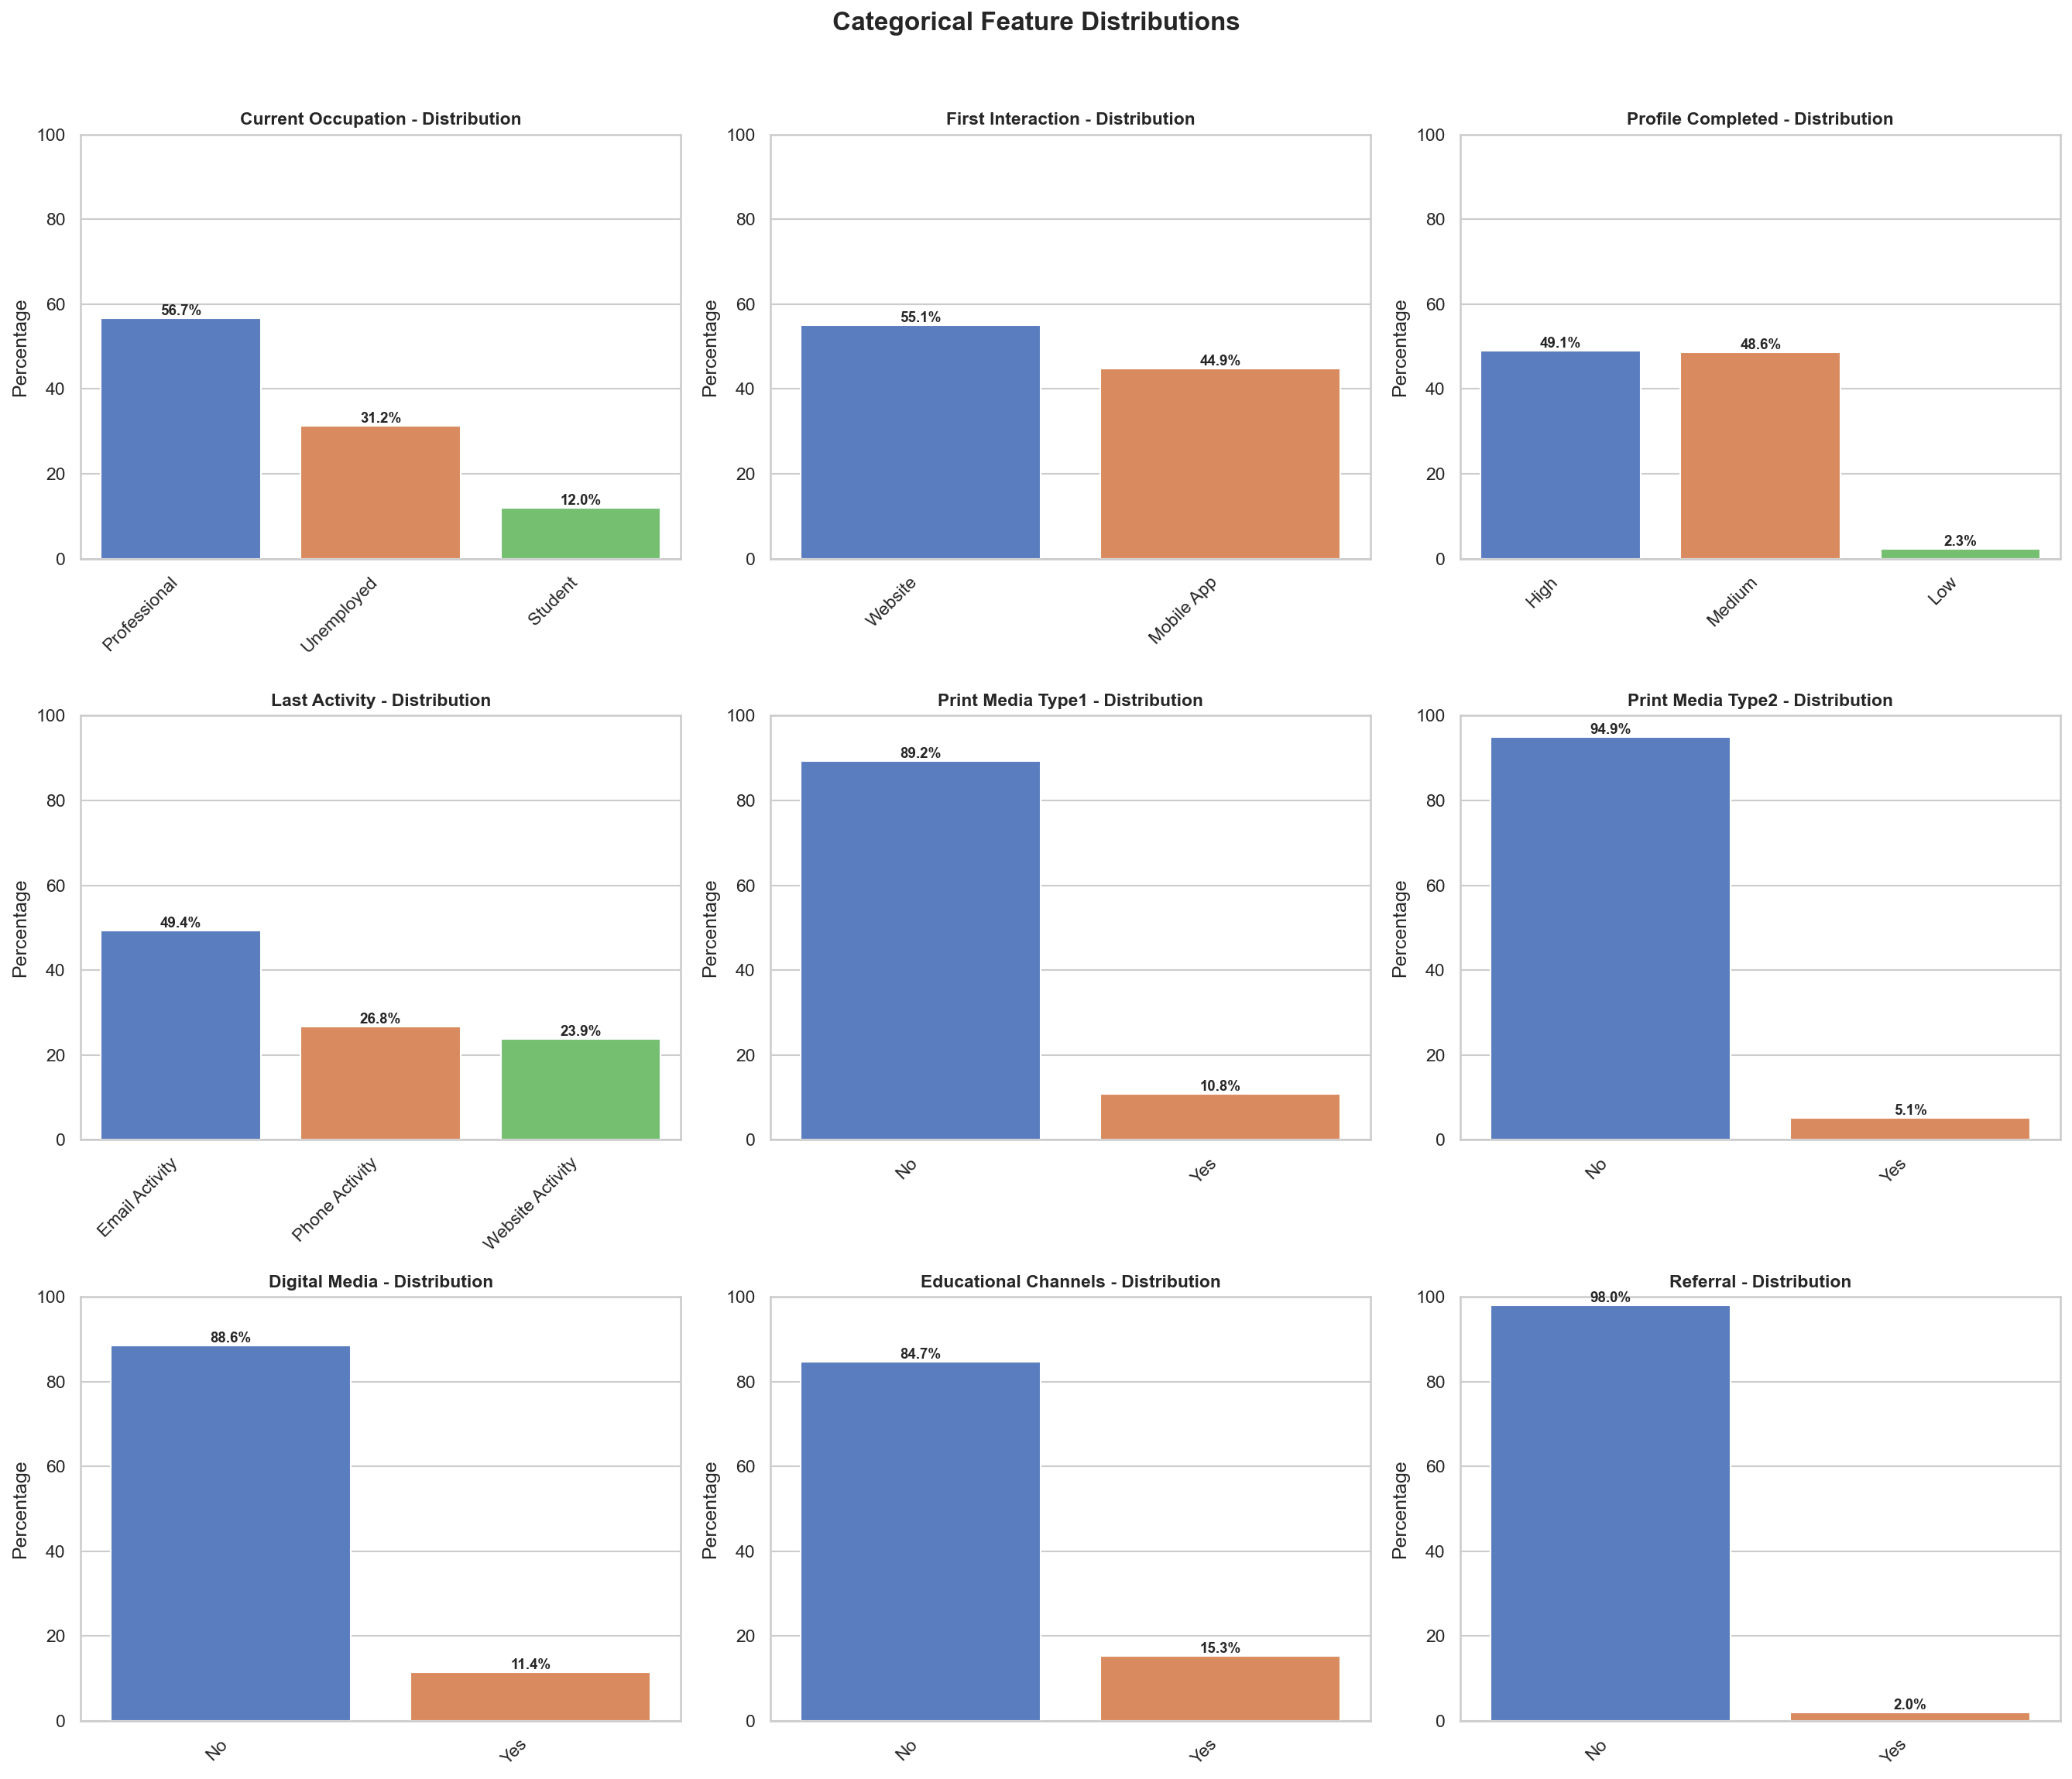

In [6]:
# Categorical Feature Distributions
n_cols = 3
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 15))
axes = axes.flatten()

# Consistent color mapping for binary Yes/No features
yes_no_palette = {
    "No": sns.color_palette("muted")[0],   # blue
    "Yes": sns.color_palette("muted")[1]   # orange
}

for i, feature in enumerate(cat_cols):
    
    # Force consistent ordering and coloring for Yes/No columns
    if set(data[feature].dropna().unique()) == {"Yes", "No"}:
        order = ["No", "Yes"]
        palette = yes_no_palette
    else:
        order = data[feature].value_counts().index
        palette = "muted"
    
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        order=order,
        hue_order=order,
        stat="percent",
        palette=palette,
        legend=False,
        ax=axes[i]
    )
    
    # Add percentage labels on top of each bar
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )
    
    # Format each subplot
    ax.set_title(
        f'{feature.replace("_", " ").title()} - Distribution',
        fontsize=11,
        fontweight="bold"
    )
    
    ax.set_ylabel("Percentage")
    ax.set_ylim(0, 100)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

    # Align rotated labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Hide unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Categorical Feature Distributions",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

**Current Occupation:** The majority of leads (57%) identify as professionals.
Unemployed leads make up the second largest group, followed by students. Together,
unemployed and student leads account for less than half the total, meaning
ExtraaLearn's audience skews heavily toward working adults.

**First Interaction:** Leads are balanced between the two channels, with the
website accounting for roughly 55% of first interactions and the mobile app
making up the remaining 45%. Neither channel dominates significantly.

**Profile Completion:** The vast majority of leads have at least a partially
completed profile. High and Medium completion are nearly equal at approximately
49% each, with Low completion representing only about 2% of leads. This suggests
most leads are genuinely engaged enough to complete their profile.

**Last Activity:** Email activity accounts for nearly half (49%) of the most
recent lead interactions, with phone and website activity at 27% and 24%
respectively. Email is clearly the dominant touchpoint.

**Media Exposure:** Paid and earned media channels show very low reach across
the board. Roughly 89% of leads were not exposed to newspaper ads, 95% not to
magazine ads, 89% not to digital media, and 85% had no connection through
educational channels. Referral activity was also minimal, with approximately 98% 
of leads not coming through a referral.

**Distribution Takeaway:** Most leads come in through owned channels, mainly the website and mobile app, while paid and earned media touch only a small fraction of the total lead pool. This puts more weight on behavioral signals like time on site, profile completion, and page views as potential predictors, since channel attribution alone will not tell the whole story. The multivariate analysis should provide additional insight.

--- 

### Correlation Analysis - Numeric Features

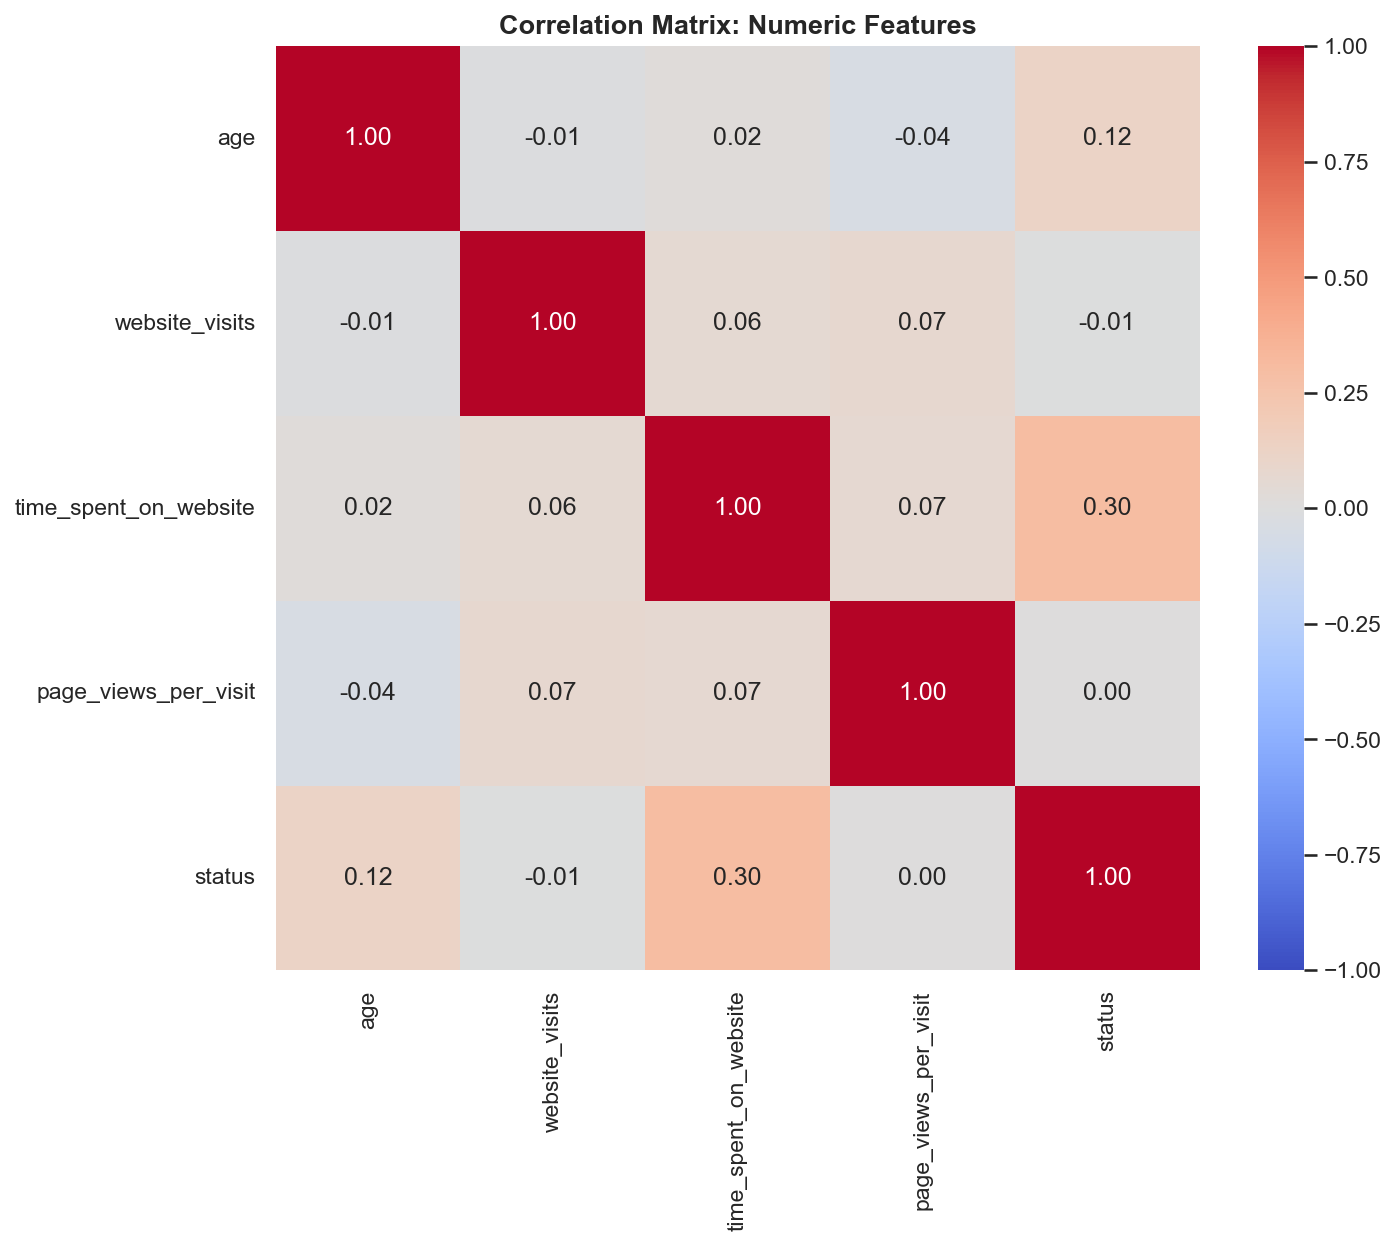

In [7]:
# Correlation matrix for numeric features and target variable
corr_features = num_cols + ["status"]
corr_matrix = data[corr_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix: Numeric Features", fontsize=13, fontweight="bold")
plt.show()

#### Observations

The numeric features do not show strong linear relationships with conversion in this heatmap. `time_spent_on_website` has the strongest relationship with the target at approximately +0.30, while `age` shows a smaller positive relationship at approximately +0.12.

This suggests that leads who spend more time on the website, and to a lesser extent older leads, may be more likely to convert. However, these relationships are moderate rather than strong, so no single numeric feature explains conversion on its own.

The numeric features also do not appear to be highly correlated with each other. This is helpful because it means the features are not simply repeating the same information.

It is important to note that a low correlation does not mean a feature is unimportant. Correlation only captures simple straight-line relationships. A feature like time spent on the website may still be very useful if the relationship with conversion is more complex. For example, the difference between a lead spending very little time on the site and a lead spending a large amount of time may matter more than the overall correlation score suggests.

---

### Multivariate Analysis

#### Conversion Rates by Category

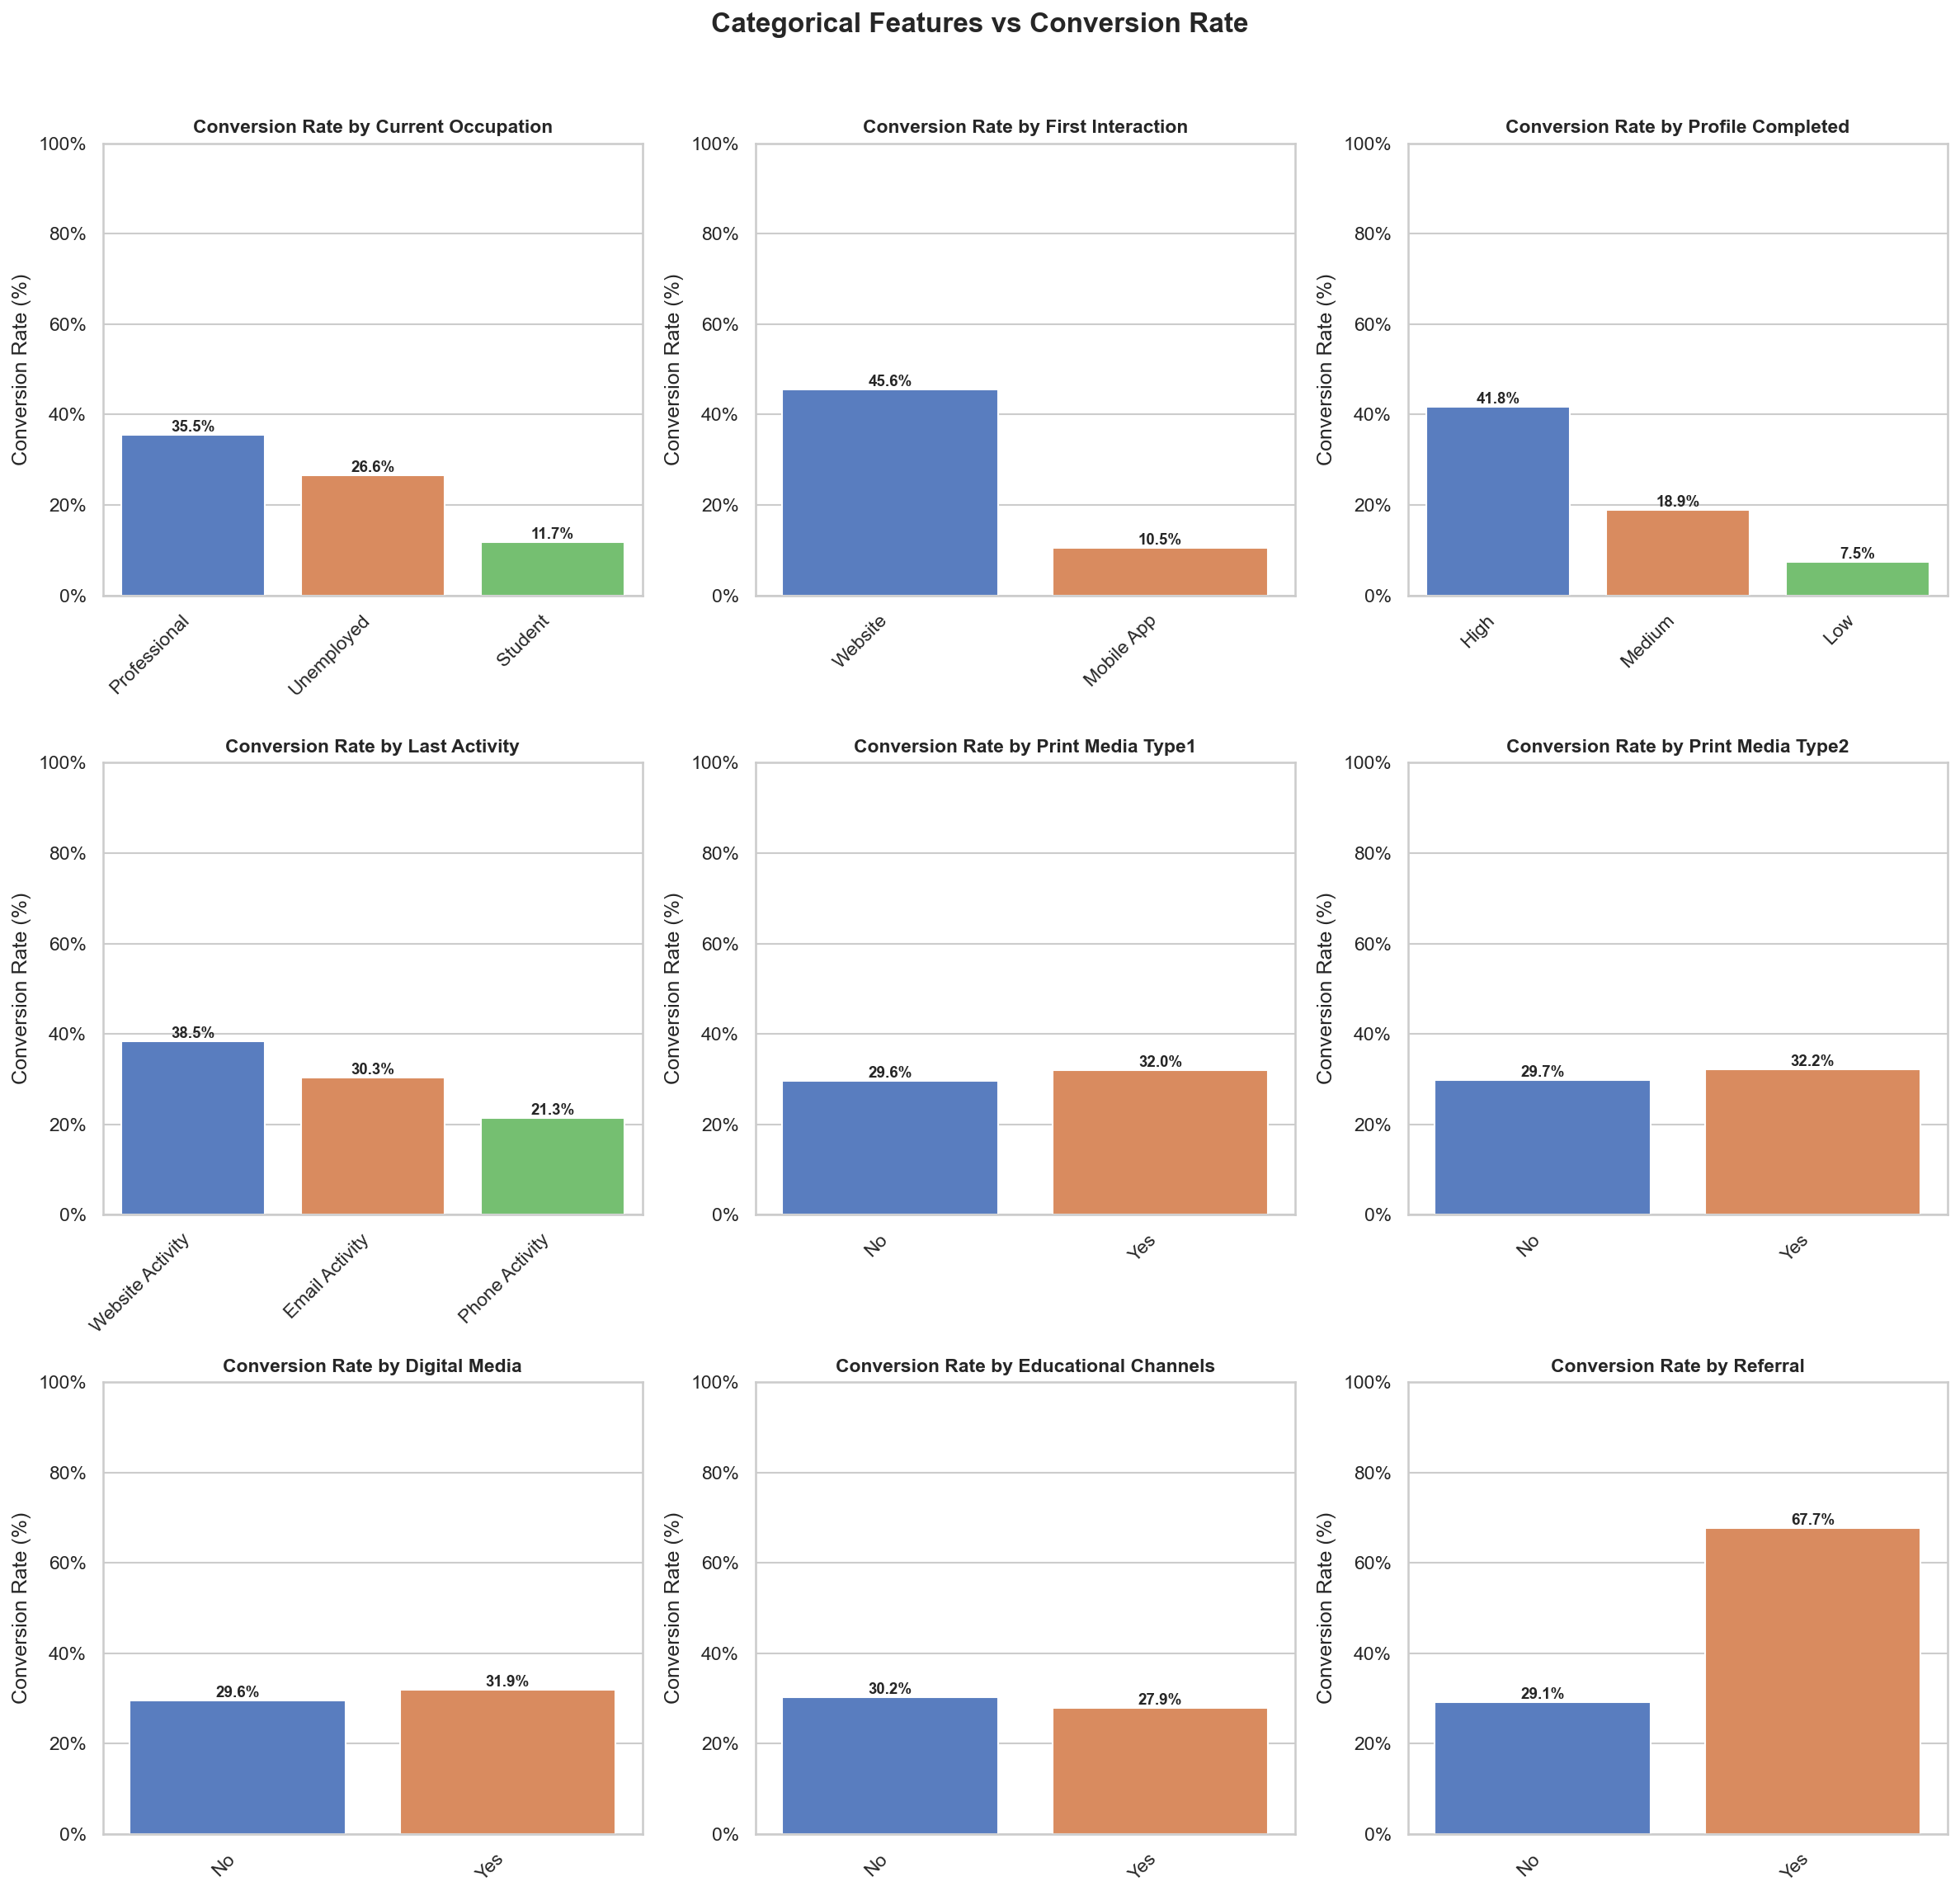

In [8]:
# Categorical Features vs Conversion Rate
n_cols = 3
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 5))
axes = axes.flatten()

# Consistent color mapping for binary Yes/No features
yes_no_palette = {
    "No": sns.color_palette("muted")[0],   # blue
    "Yes": sns.color_palette("muted")[1]   # orange
}

for i, feature in enumerate(cat_cols):
    
    # Calculate conversion rates by category
    conversion_rates = (
        data.groupby(feature)["status"]
        .mean()
        .reset_index()
    )
    
    # Force consistent ordering and coloring for Yes/No columns
    if set(data[feature].dropna().unique()) == {"Yes", "No"}:
        order = ["No", "Yes"]
        palette = yes_no_palette
    else:
        order = conversion_rates.sort_values("status", ascending=False)[feature]
        palette = "muted"
    
    # Create conversion rate bar plot
    ax = sns.barplot(
        data=conversion_rates,
        x=feature,
        y="status",
        hue=feature,
        order=order,
        hue_order=order,
        palette=palette,
        legend=False,
        ax=axes[i]
    )
    
    # Add percentage labels on top of each bar
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height() * 100:.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )
    
    # Format each subplot
    ax.set_title(
        f'Conversion Rate by {feature.replace("_", " ").title()}',
        fontsize=11,
        fontweight="bold"
    )
    
    ax.set_ylabel("Conversion Rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.tick_params(axis="x", rotation=45)
    
    # Align rotated labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Hide unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Categorical Features vs Conversion Rate",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

The categorical features show several clear differences in conversion rates across lead groups.

**Strongest signals:**  
The largest gaps appear in `first_interaction`, `profile_completed`, and `referral`.

* Leads whose first interaction was through the **website** converted at approximately **45.6%**, compared with approximately **10.5%** for leads whose first interaction was through the **mobile app**. This is one of the clearest categorical differences in the data.
* Leads with **high profile completion** converted at approximately **41.8%**, compared with approximately **18.9%** for medium completion and **7.5%** for low completion. This suggests that profile completion is a strong sign of interest.
* **Referral leads** had the highest conversion rate of any category at approximately **67.7%**, although they represent a very small portion of the overall dataset.

**Moderate signals:**  
Occupation and last activity also show meaningful differences.

* **Professionals** converted at approximately **35.5%**, which is higher than unemployed leads and students. This may reflect stronger career motivation or greater ability to pay for a program.
* Leads with recent **website activity** converted at the highest rate among last activity groups, followed by email activity and then phone activity. This suggests that recent self-directed engagement may be more valuable than passive or follow-up contact alone.

**Weaker signals:**  
The media exposure variables show smaller differences in conversion. Print media, digital media, and educational channel exposure do not appear to separate converters from non-converters as clearly as website behavior, profile completion, or referrals.

---

#### Numeric Features by Conversion Status

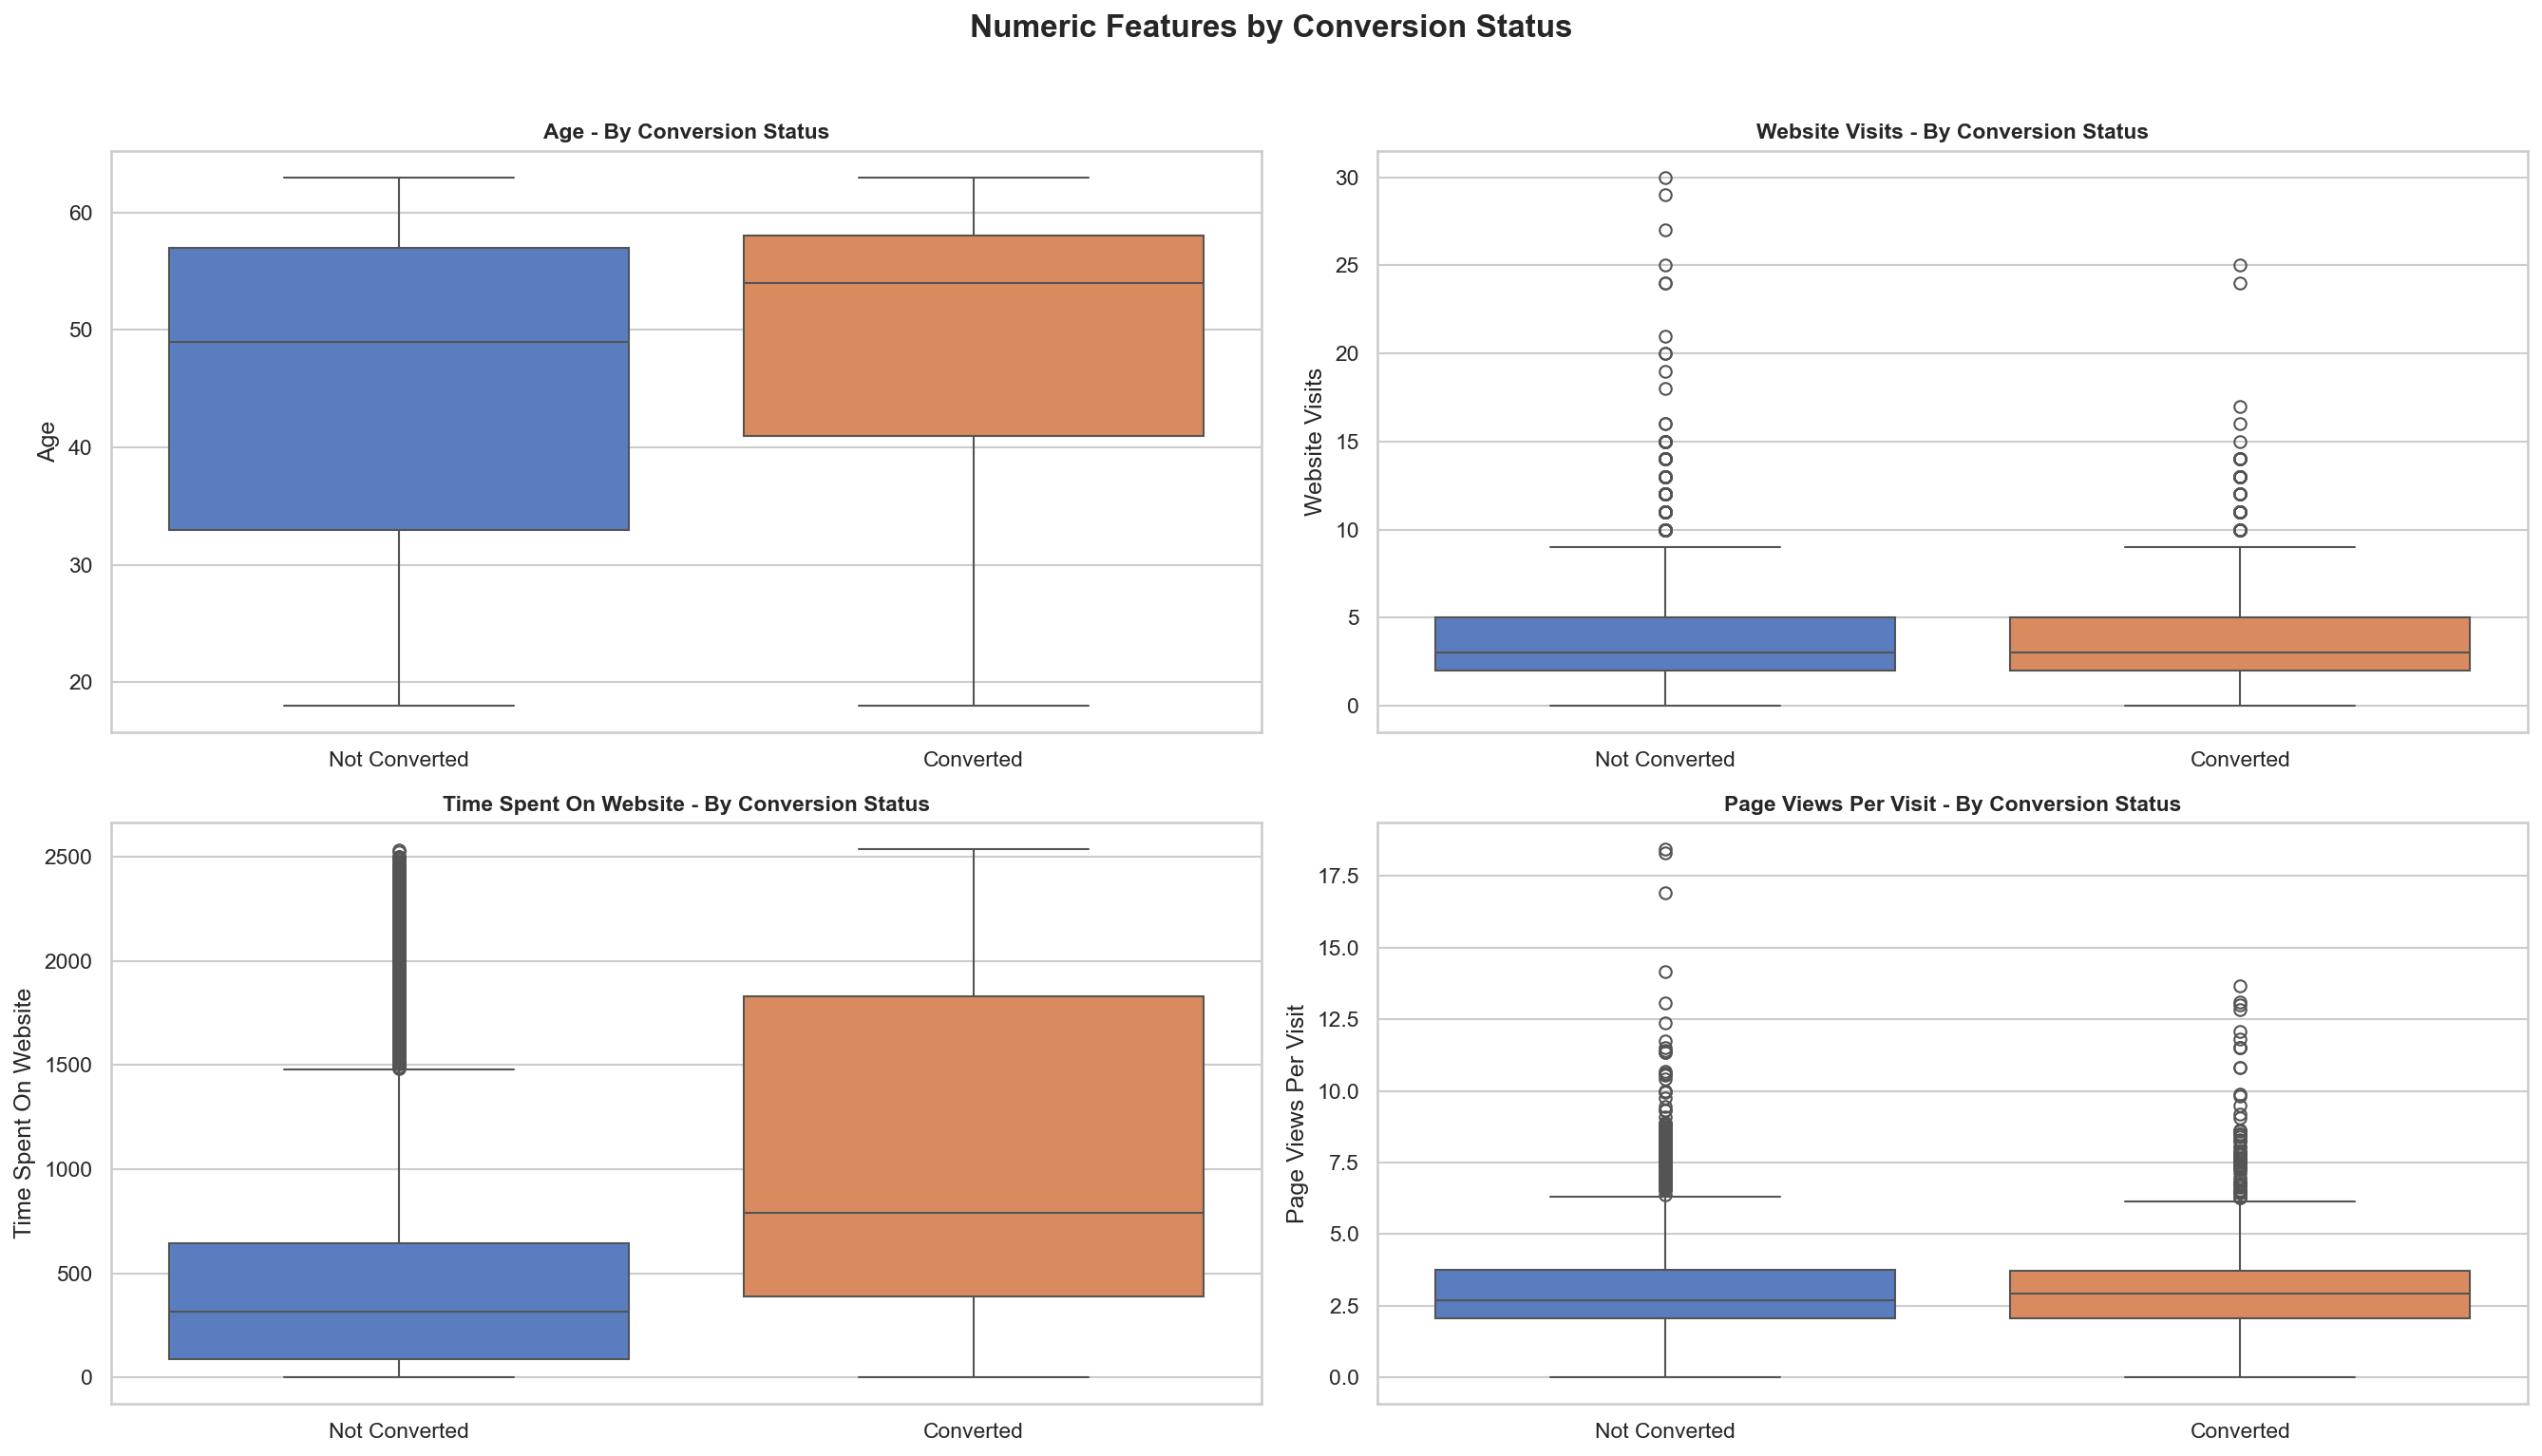

In [9]:
# Numeric Features vs Conversion Status
n_cols = 2
n_rows = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
axes = axes.flatten()

# Consistent color mapping for conversion status
status_palette = {
    0: sns.color_palette("muted")[0],   # Not Converted
    1: sns.color_palette("muted")[1]    # Converted
}

for i, feature in enumerate(num_cols):
    
    ax = sns.boxplot(
        data=data,
        x="status",
        y=feature,
        hue="status",
        order=[0, 1],
        hue_order=[0, 1],
        palette=status_palette,
        legend=False,
        ax=axes[i]
    )
    
    ax.set_title(
        f'{feature.replace("_", " ").title()} - By Conversion Status',
        fontsize=11,
        fontweight="bold"
    )
    
    ax.set_xlabel("")
    ax.set_ylabel(feature.replace("_", " ").title())
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Not Converted", "Converted"])

# Hide unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Numeric Features by Conversion Status",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

The numeric features show different levels of separation between converted and non-converted leads.

**Age:**
Converted leads tend to be slightly older than non-converted leads. The difference is not large, but it suggests that older leads may be somewhat more likely to convert. This could reflect greater career focus, financial readiness, or stronger motivation to invest in additional education.

**Website Visits:**
Website visit counts look very similar for converted and non-converted leads. This suggests that the number of visits alone is not a strong signal of conversion. However, the non-converted group includes several high visit outliers, which may indicate leads who return often but still do not take the next step. These leads may be good candidates for targeted follow-up or additional nurturing.

**Time Spent on Website:**
Time spent on the website shows the clearest difference between the two groups. Converted leads generally spend more time on the site than non-converted leads, making this one of the strongest numeric indicators of conversion intent.

**Page Views per Visit:**
Page views per visit does not separate the two groups as clearly. Similar to website visits, it may not be very strong on its own, but it could still add value when combined with other engagement signals.

---

## Preprocessing & Feature Engineering

Based on the data audit and exploratory analysis, the dataset is ready to be prepared for modeling. This section reviews the remaining data preparation decisions, creates a few business-focused features, and sets up the data so the model can be trained and evaluated properly.

The preparation steps are organized as follows:

1. **Missing Values:** confirm that no missing value treatment is needed.
2. **Outlier Review:** identify unusually high values and decide how they should be handled during modeling.
3. **Skewness Check:** review whether any numeric features may need additional treatment.
4. **Rule-Based Feature Engineering:** create simple features that can be safely added before the train/test split.
5. **Feature and Target Setup:** separate the model inputs from the conversion outcome.
6. **Train/Test Split:** split the data so model performance can be tested on records it has not seen before.
7. **Post-Split Preparation:** apply any data-driven steps, such as outlier capping, scaling, and training-based feature creation, using the training data only.



### Missing Values

The data audit confirmed that there are no missing values in the dataset. No imputation or row removal is needed before modeling.


### Outlier Review

Before changing the data, the numeric features are reviewed for unusually high or low values using the IQR method. This helps identify whether any features have extreme values that could overly influence model training.

In [10]:
# Review numeric outliers using the IQR method
outlier_summary = []

for num in num_cols:
    
    Q1, Q3 = data[num].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((data[num] < lower) | (data[num] > upper)).sum()
    pct = outliers / len(data) * 100
    
    outlier_summary.append({
        "Feature": num,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers": outliers,
        "% Outliers": pct
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

,Feature,Lower Bound,Upper Bound,Outliers,% Outliers
0,age,4.50,88.50,0,0.00
1,website_visits,-2.50,9.50,154,3.34
2,time_spent_on_website,-1633.25,3118.75,0,0.00
3,page_views_per_visit,-0.44,6.27,257,5.57


#### Outlier Treatment Decision

The outlier review shows that most numeric features are within a reasonable range. `age` and `time_spent_on_website` do not show outliers based on the IQR method.

The clearest outlier patterns appear in `website_visits` and `page_views_per_visit`. These are high-end outliers, meaning a small number of leads visited the website or viewed pages much more often than the typical lead.

These values appear to represent real lead behavior rather than data errors. For example, a lead with many website visits may be highly interested but still undecided. Because these records are valid business observations, they should not be removed.

Instead, the extreme values will be capped after the train/test split using IQR bounds calculated from the training data only. Those same bounds will then be applied to both the training and test sets. This keeps the test set from influencing preprocessing decisions and follows a stricter machine learning workflow.

### Skewness Check

After reviewing outliers, the next step is to check whether the numeric features are heavily skewed and may need transformation later in the modeling workflow.

In [11]:
# Review skewness of original numeric features before modeling

skewness = data[num_cols].skew().round(2)

skewness_summary = pd.DataFrame({
    "Skewness": skewness
})

display(skewness_summary)

,Skewness
age,-0.72
website_visits,2.16
time_spent_on_website,0.95
page_views_per_visit,1.27


#### Observations

The numeric features show different levels of skewness. `website_visits` is notably right-skewed at **2.16**, which matches the EDA finding that a smaller group of leads visited the website much more often than the typical lead.

`page_views_per_visit` is moderately right-skewed at **1.27**, while `time_spent_on_website` is mildly right-skewed at **0.95**. `age` is slightly left-skewed at **-0.72**.

No log transformation is applied at this stage. Instead, the most extreme high-end values will be capped after the train/test split using training-data bounds only. This keeps the treatment consistent with the strict train/test workflow while reducing the influence of the heaviest tails.

---

### Rule-Based Feature Engineering

#### Binary Encoding

Several categorical features contain only `Yes` and `No` values. These columns are converted to `1` and `0` so they can be used directly in modeling and feature engineering.

This is a fixed rule-based transformation, not a learned transformation, so it can be applied before the train/test split without leaking information from the test set.


In [12]:
# Create a modeling copy for rule-based transformations
model_data = data.copy()

# Encode Yes/No categorical features as 1/0 for modeling
binary_cols = [
    "print_media_type1",
    "print_media_type2",
    "digital_media",
    "educational_channels",
    "referral"
]

# Apply a rerun-safe binary mapping to the modeling dataset
for col in binary_cols:
    model_data[col] = model_data[col].replace({"Yes": 1, "No": 0}).astype(int)

# Preview encoded columns
display(model_data[binary_cols].head())

# Verify that each binary column now contains only 0 and 1
print("Unique values after binary encoding:")
for col in binary_cols:
    values = [int(x) for x in sorted(model_data[col].dropna().unique())]
    print(f"{col}: {values}")

# Confirm the mapping did not create missing values
print("\nMissing values after binary encoding:")
print(model_data[binary_cols].isna().sum())

,print_media_type1,print_media_type2,digital_media,educational_channels,referral
0,1,0,1,0,0
1,0,0,0,1,0
2,0,0,1,0,0
3,0,0,0,0,0
4,0,0,0,0,0


Unique values after binary encoding:
print_media_type1: [0, 1]
print_media_type2: [0, 1]
digital_media: [0, 1]
educational_channels: [0, 1]
referral: [0, 1]

Missing values after binary encoding:
print_media_type1       0
print_media_type2       0
digital_media           0
educational_channels    0
referral                0
dtype: int64


#### Summary

The Yes/No columns were successfully converted into binary `1` and `0` values in `model_data`. The validation check confirms that each encoded column contains only `0` and `1`, with no missing values introduced during the transformation.

This prepares the media exposure and referral fields for later feature engineering and modeling.

---

#### Marketing Touch Count

The media exposure fields are combined into a single `marketing_touch_count` feature. This counts how many marketing or media channels touched each lead. A lead with multiple exposures may behave differently from a lead with no exposure.

In [13]:
# Create a marketing touch count from the encoded media exposure columns
media_cols = [
    "print_media_type1",
    "print_media_type2",
    "digital_media",
    "educational_channels"
]

# Sum the media exposure fields to count total marketing touches per lead
model_data["marketing_touch_count"] = model_data[media_cols].sum(axis=1)

# Preview the new feature
display(model_data[media_cols + ["marketing_touch_count"]].head())

,print_media_type1,print_media_type2,digital_media,educational_channels,marketing_touch_count
0,1,0,1,0,2
1,0,0,0,1,1
2,0,0,1,0,1
3,0,0,0,0,0
4,0,0,0,0,0


In [14]:
# Review distribution of marketing touch count
touch_count_summary = (
    model_data["marketing_touch_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Marketing Touch Count")
    .reset_index(name="Lead Count")
)

display(touch_count_summary.style.hide(axis="index"))

Marketing Touch Count,Lead Count
0,2943
1,1404
2,239
3,24
4,2


#### Summary

The `marketing_touch_count` feature gives the model a simple measure of total marketing exposure while keeping the original channel fields available.

Most leads had either zero or one marketing touch, while very few had exposure across multiple media channels. This confirms that marketing exposure is relatively limited in the dataset.

---

#### Engagement Score Design

The behavioral website features represent different types of engagement:

* `website_visits`: how often a lead returned to the website
* `time_spent_on_website`: how much time the lead spent engaging with the site
* `page_views_per_visit`: how deeply the lead browsed during visits

These features are measured on different scales, so they should not be added together directly. For example, `time_spent_on_website` has much larger values than `website_visits`, so it would dominate the score if the features were combined without scaling.

To avoid data leakage, the final scaled `engagement_score` will be created after the train/test split. The scaler should be fit on the training data only, then applied to both the training and test sets.


In [15]:
# Define website behavior features that will be used to create the engagement score later

engagement_components = [
    "website_visits",
    "time_spent_on_website",
    "page_views_per_visit"
]

# Preview the engagement components
display(model_data[engagement_components].head())

# Review summary statistics before scaling
display(model_data[engagement_components].describe().T)

,website_visits,time_spent_on_website,page_views_per_visit
0,7,1639,1.86
1,2,83,0.32
2,3,330,0.07
3,4,464,2.06
4,4,600,16.91


,count,mean,std,min,25%,50%,75%,max
website_visits,4612.00,3.57,2.83,0.00,2.00,3.00,5.00,30.00
time_spent_on_website,4612.00,724.01,743.83,0.00,148.75,376.00,1336.75,2537.00
page_views_per_visit,4612.00,3.03,1.97,0.00,2.08,2.79,3.76,18.43


#### Summary

The engagement score will combine website visits, time spent on the website, and page views per visit into one overall measure of lead engagement. Because these features use different scales, the score will be created after the train/test split using scaling fit on the training data only.

---


#### High Intent Flag Design

A high-intent flag will be created to identify leads who show both strong profile commitment and strong website engagement.

The feature will combine two signals:

- `profile_completed` equals `High`
- `time_spent_on_website` is above the training-set median

The flag is intentionally simple and business-friendly. A lead who completes their profile and spends meaningful time on the website is likely showing stronger buying intent than a lead who only does one of those things.

To avoid data leakage, the time threshold will be calculated after the train/test split using the training data only. The same threshold will then be applied to both the training and test sets.

In [16]:
# Define components for the high intent flag

high_intent_profile_value = "High"
high_intent_time_feature = "time_spent_on_website"

print("High intent flag will be based on:")
print(f"1. profile_completed == '{high_intent_profile_value}'")
print(f"2. {high_intent_time_feature} > training-set median")

High intent flag will be based on:
1. profile_completed == 'High'
2. time_spent_on_website > training-set median


#### Summary

The high-intent flag is designed to capture leads who show both profile commitment and meaningful website engagement. The feature will be created after the train/test split so the time-spent threshold is learned only from the training data.

### Feature and Target Setup

Before splitting the data, the target variable is separated from the modeling features. The `ID` column is excluded from the modeling features because it is only a unique lead identifier and does not provide predictive value.

However, the ID values are saved separately because they may be useful later when creating a scored or ranked lead list.

In [17]:
# Preserve lead IDs for later scoring or ranked lead output
lead_ids = model_data["ID"].copy()

# Separate predictor features and target variable
X = model_data.drop(columns=["ID", "status"])
y = model_data["status"]

# Review modeling features
print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")

print("\nModeling features:")
print(X.columns.tolist())

Feature matrix shape: (4612, 14)
Target shape: (4612,)

Modeling features:
['age', 'current_occupation', 'first_interaction', 'profile_completed', 'website_visits', 'time_spent_on_website', 'page_views_per_visit', 'last_activity', 'print_media_type1', 'print_media_type2', 'digital_media', 'educational_channels', 'referral', 'marketing_touch_count']


#### Summary

The modeling features and target variable are now separated. The `ID` column is saved for later lead scoring, but excluded from model training because it is only a unique identifier.

At this point, `X` includes only rule-based transformations. Data-driven steps will be handled after the train/test split.

### Train/Test Split

The data is split into training and testing sets before any data-driven preprocessing is applied. This protects the test set so it can serve as a fair evaluation of how the model performs on unseen leads.

A stratified 70/30 split is used so the converted vs. non-converted ratio stays consistent in both the training and test sets.

In [18]:
# Split features and target into training and testing sets
X_train, X_test, y_train, y_test, lead_ids_train, lead_ids_test = train_test_split(
    X,
    y,
    lead_ids,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (3228, 14)
X_test shape:  (1384, 14)
y_train shape: (3228,)
y_test shape:  (1384,)


In [19]:
# Confirm the target distribution stayed consistent after the split
split_summary = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True).sort_index() * 100,
    "Training Set": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test Set": y_test.value_counts(normalize=True).sort_index() * 100
})

split_summary.index = ["Not Converted (0)", "Converted (1)"]

display(split_summary.round(2))

,Full Dataset,Training Set,Test Set
Not Converted (0),70.14,70.14,70.16
Converted (1),29.86,29.86,29.84


#### Summary

The dataset has been split into training and testing sets using a stratified split. This keeps the conversion rate consistent across the full dataset, training set, and test set.

From this point forward, data-driven preparation steps will be learned from the training data only and then applied to the test data.

### Post-Split Outlier Capping

Outlier caps are calculated using the training data only. The same caps are then applied to both the training and test sets.

This keeps the test set from influencing preprocessing decisions while still reducing the impact of unusually large numeric values during modeling.

In [20]:
# Calculate IQR outlier caps from the training data only
outlier_caps = {}

for num in num_cols:
    
    Q1, Q3 = X_train[num].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier_caps[num] = {
        "Lower Bound": lower,
        "Upper Bound": upper
    }

outlier_caps_df = pd.DataFrame(outlier_caps).T

display(outlier_caps_df.round(2))

,Lower Bound,Upper Bound
age,4.50,88.50
website_visits,-2.50,9.50
time_spent_on_website,-1614.25,3099.75
page_views_per_visit,-0.43,6.28


In [21]:
# Apply training-data outlier caps to both training and test sets
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

for num in num_cols:
    
    lower = outlier_caps[num]["Lower Bound"]
    upper = outlier_caps[num]["Upper Bound"]
    
    X_train_capped[num] = X_train_capped[num].clip(lower, upper)
    X_test_capped[num] = X_test_capped[num].clip(lower, upper)

print("Outlier capping applied using training-data bounds.")

Outlier capping applied using training-data bounds.


In [22]:
# Compare original and capped maximum values
cap_comparison = pd.DataFrame({
    "Train Original Max": X_train[num_cols].max(),
    "Train Capped Max": X_train_capped[num_cols].max(),
    "Test Original Max": X_test[num_cols].max(),
    "Test Capped Max": X_test_capped[num_cols].max(),
    "Training Upper Bound": outlier_caps_df["Upper Bound"]
})

display(cap_comparison.round(2))

,Train Original Max,Train Capped Max,Test Original Max,Test Capped Max,Training Upper Bound
age,63.00,63.00,63.00,63.00,88.50
website_visits,30.00,9.50,25.00,9.50,9.50
time_spent_on_website,2537.00,2537.00,2529.00,2529.00,3099.75
page_views_per_visit,18.43,6.28,12.84,6.28,6.28


#### Summary

Outlier caps were calculated from the training data only and then applied to both the training and test sets. The capped versions, `X_train_capped` and `X_test_capped`, will be used for the next post-split feature engineering steps.

### Post-Split Engagement Score

The engagement score combines the main website behavior features into one overall measure of lead engagement.

Because the components are measured on different scales, they are normalized before being combined. The scaler is fit on the training data only, then applied to both the training and test sets. This keeps the test set from influencing the feature creation process.

In [23]:
# Create engagement score using scaler fit on training data only
engagement_components = [
    "website_visits",
    "time_spent_on_website",
    "page_views_per_visit"
]

# Create copies so the capped datasets remain available if needed
X_train_fe = X_train_capped.copy()
X_test_fe = X_test_capped.copy()

# Fit scaler on training data only
engagement_scaler = MinMaxScaler()
X_train_scaled_engagement = engagement_scaler.fit_transform(X_train_fe[engagement_components])

# Apply the same scaler to test data
X_test_scaled_engagement = engagement_scaler.transform(X_test_fe[engagement_components])

# Sum scaled components to create engagement score
X_train_fe["engagement_score"] = X_train_scaled_engagement.sum(axis=1)
X_test_fe["engagement_score"] = X_test_scaled_engagement.sum(axis=1)

# Preview new feature
display(X_train_fe[engagement_components + ["engagement_score"]].head())

,website_visits,time_spent_on_website,page_views_per_visit,engagement_score
1996,5.00,457,2.16,1.05
1015,6.00,359,5.55,1.66
3294,0.00,0,0.00,0.00
4116,0.00,0,0.00,0.00
1695,1.00,578,2.11,0.67


In [24]:
# Review engagement score distribution in training and test sets
engagement_summary = pd.DataFrame({
    "Train": X_train_fe["engagement_score"].describe(),
    "Test": X_test_fe["engagement_score"].describe()
})

display(engagement_summary.round(2))

,Train,Test
count,3228.00,1384.00
mean,1.12,1.09
std,0.50,0.50
min,0.00,0.00
25%,0.77,0.77
50%,1.11,1.06
75%,1.45,1.42
max,2.94,2.74


#### Summary

The `engagement_score` feature was created using website visits, time spent on the website, and page views per visit. Each component was scaled before being combined so that no single feature dominates the score simply because it has larger values.

The scaler was fit on the training data only and then applied to the test data.

### Post-Split High Intent Flag

The high-intent flag identifies leads who show both profile commitment and meaningful website engagement.

The feature is based on two conditions:

- `profile_completed` equals `High`
- `time_spent_on_website` is above the training-set median

The time-spent threshold is calculated from the training data only, then applied to both the training and test sets.

In [25]:
# Create high intent flag using training-set median only

# Calculate threshold from training data only
time_spent_median_train = X_train_fe["time_spent_on_website"].median()

# Create high intent flag for training and test sets
X_train_fe["high_intent_flag"] = (
    (X_train_fe["profile_completed"] == "High") &
    (X_train_fe["time_spent_on_website"] > time_spent_median_train)
).astype(int)

X_test_fe["high_intent_flag"] = (
    (X_test_fe["profile_completed"] == "High") &
    (X_test_fe["time_spent_on_website"] > time_spent_median_train)
).astype(int)

print(f"Training-set median time spent on website: {time_spent_median_train:.2f}")

display(
    X_train_fe[
        ["profile_completed", "time_spent_on_website", "high_intent_flag"]
    ].head()
)

Training-set median time spent on website: 374.00


,profile_completed,time_spent_on_website,high_intent_flag
1996,High,457,1
1015,High,359,0
3294,Medium,0,0
4116,Medium,0,0
1695,High,578,1


In [26]:
# Review high intent flag distribution

high_intent_summary = pd.DataFrame({
    "Train Count": X_train_fe["high_intent_flag"].value_counts().sort_index(),
    "Train %": X_train_fe["high_intent_flag"].value_counts(normalize=True).sort_index() * 100,
    "Test Count": X_test_fe["high_intent_flag"].value_counts().sort_index(),
    "Test %": X_test_fe["high_intent_flag"].value_counts(normalize=True).sort_index() * 100
})

high_intent_summary.index = ["Not High Intent (0)", "High Intent (1)"]

display(high_intent_summary.round(2))

,Train Count,Train %,Test Count,Test %
Not High Intent (0),2401,74.38,1025,74.06
High Intent (1),827,25.62,359,25.94


#### Summary

The `high_intent_flag` feature was created using a training-set threshold for time spent on the website. Leads are flagged as high intent when they have a completed profile and spend more time on the website than the training-set median.

This adds a simple business-friendly signal for the model while keeping the threshold based on training data only.

### Final Preprocessing Pipeline

The final preprocessing pipeline prepares the feature set for modeling. Numeric features are scaled, and remaining categorical features are one-hot encoded.

The binary media/referral features, `marketing_touch_count`, `engagement_score`, and `high_intent_flag` are already numeric, so they are handled with the numeric feature group rather than one-hot encoded.

In [27]:
# Identify final numeric and categorical features for preprocessing
numeric_features = X_train_fe.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train_fe.select_dtypes(include=["object", "string"]).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['age', 'website_visits', 'time_spent_on_website', 'page_views_per_visit', 'print_media_type1', 'print_media_type2', 'digital_media', 'educational_channels', 'referral', 'marketing_touch_count', 'engagement_score', 'high_intent_flag']

Categorical features:
['current_occupation', 'first_interaction', 'profile_completed', 'last_activity']


In [28]:
# Build preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [29]:
# Fit preprocessing pipeline on training data only and transform both sets
X_train_processed = preprocessor.fit_transform(X_train_fe)
X_test_processed = preprocessor.transform(X_test_fe)

print(f"Processed training shape: {X_train_processed.shape}")
print(f"Processed test shape:     {X_test_processed.shape}")

Processed training shape: (3228, 23)
Processed test shape:     (1384, 23)


#### Summary

The preprocessing pipeline scales numeric features and one-hot encodes categorical features. It is fit on the training data only, then applied to the test data.

---

## Modeling & Model Evaluation

With preprocessing defined, the next step is to train several classification models and compare their performance. Each model is built inside a scikit-learn `Pipeline` so the same preprocessing steps are applied consistently before model training.

Using pipelines helps keep the workflow clean and reduces the risk of applying preprocessing differently across models. The models will be compared using metrics that are more appropriate for this imbalanced classification problem: Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [30]:
# Define baseline models for comparison
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        random_state=42
    ),
    
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
}

In [31]:
# Helper function to evaluate classification models

def evaluate_model(model_name, pipeline, X_train, X_test, y_train, y_test):
    """
    Fits a model pipeline and returns key classification metrics.
    """
    
    # Fit pipeline on training data
    pipeline.fit(X_train, y_train)
    
    # Predict class labels
    y_pred = pipeline.predict(X_test)
    
    # Predict probabilities for the positive class
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    results = {
        "Model": model_name,
        "Accuracy": pipeline.score(X_test, y_test),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)
    }
    
    return results

In [32]:
# Train and evaluate each model using the same preprocessing pipeline
model_results = []

trained_pipelines = {}

for model_name, model in models.items():
    
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )
    
    results = evaluate_model(
        model_name=model_name,
        pipeline=pipeline,
        X_train=X_train_fe,
        X_test=X_test_fe,
        y_train=y_train,
        y_test=y_test
    )
    
    model_results.append(results)
    trained_pipelines[model_name] = pipeline

# Convert results to DataFrame
model_results_df = pd.DataFrame(model_results)

# Sort by ROC-AUC for initial comparison
model_results_df = model_results_df.sort_values("ROC-AUC", ascending=False)

display(model_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
3,Gradient Boosting,0.86,0.78,0.75,0.77,0.93,0.84
2,Random Forest,0.85,0.78,0.68,0.73,0.91,0.82
4,XGBoost,0.84,0.75,0.70,0.72,0.91,0.81
0,Logistic Regression,0.80,0.63,0.82,0.71,0.88,0.76
1,Decision Tree,0.80,0.66,0.69,0.67,0.77,0.55


### Baseline Model Comparison Visual

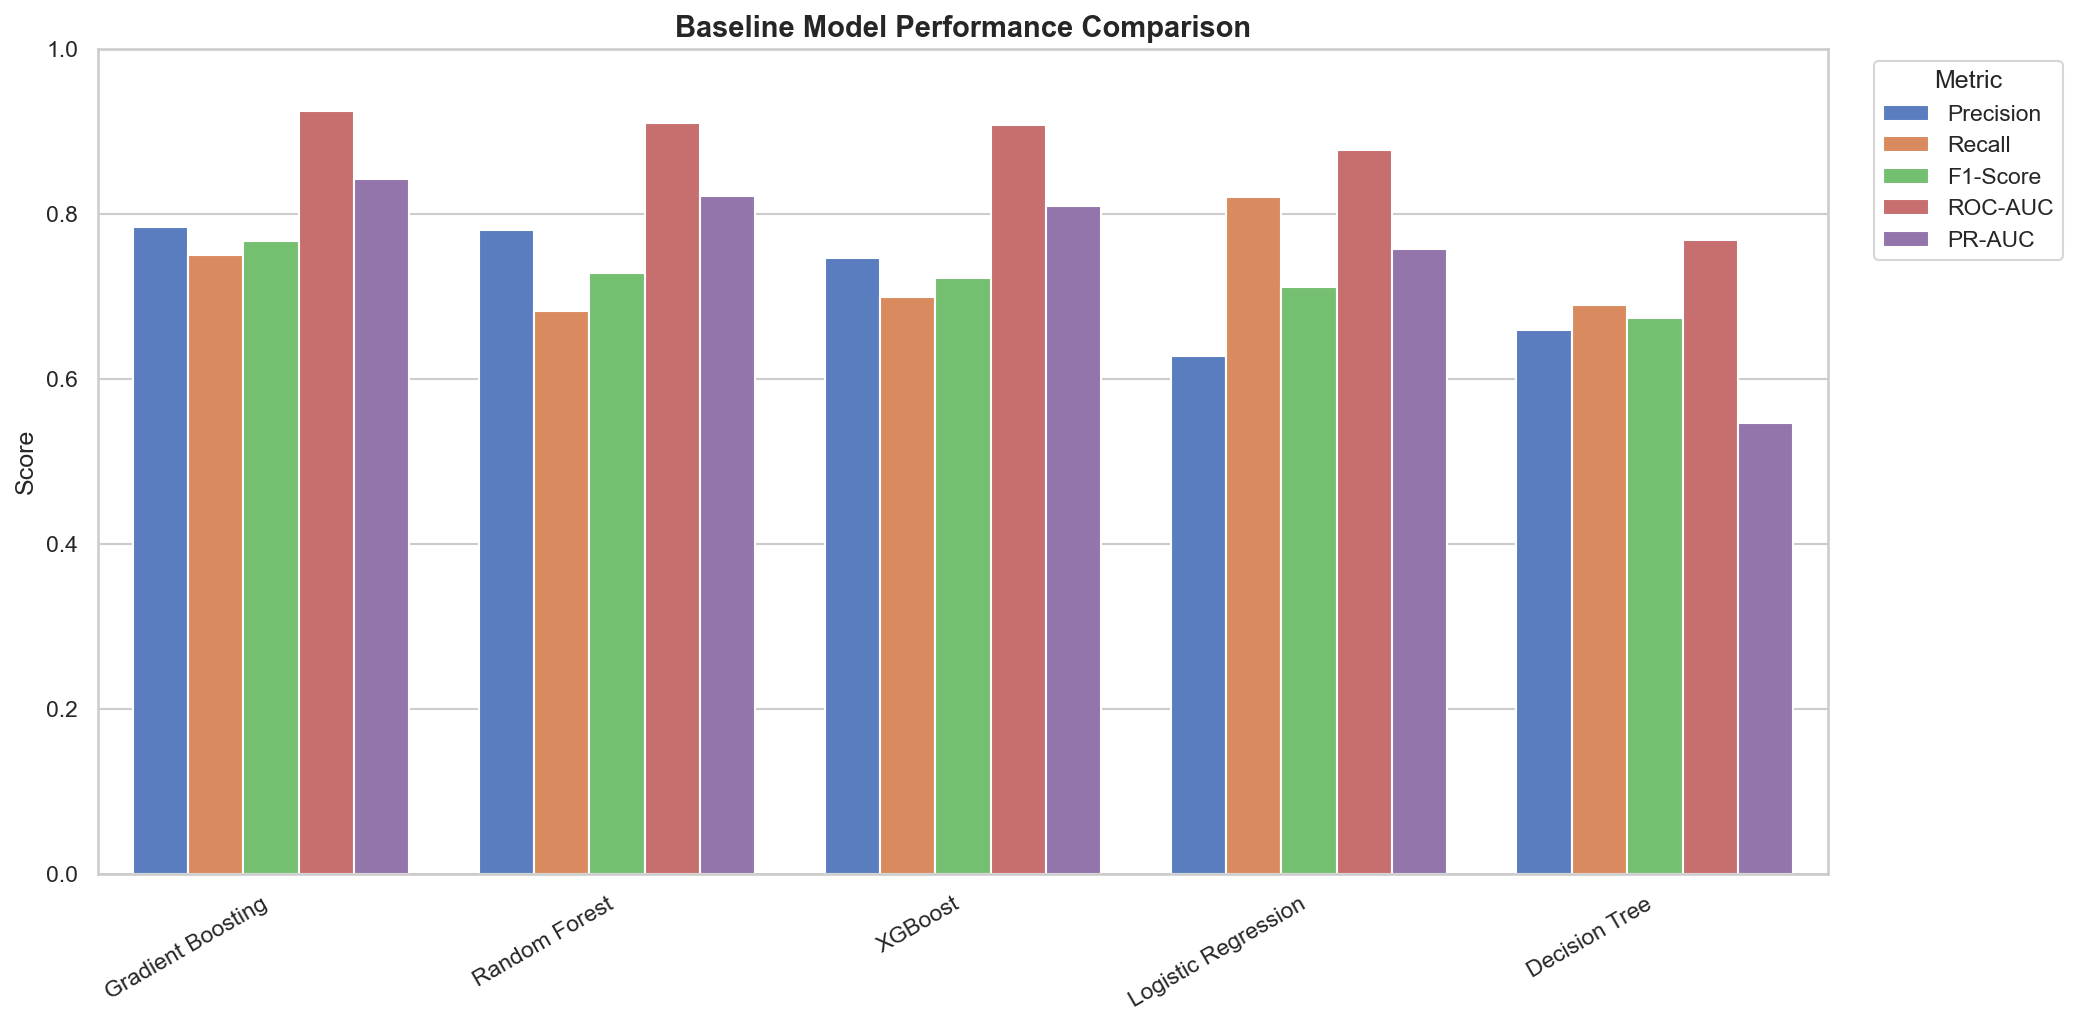

In [33]:
# Visualize baseline model performance across key metrics

metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]

model_results_long = model_results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=model_results_long,
    x="Model",
    y="Score",
    hue="Metric"
)

ax.set_title("Baseline Model Performance Comparison", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Observations

The baseline comparison shows how each model balances precision, recall, and overall ranking ability. Accuracy is reviewed, but it is not the deciding metric because the target is imbalanced.

Recall is especially important for this project because the business goal is to identify as many likely converters as possible. Precision still matters because it reflects how clean the sales call list is, but missing real converters is the more expensive mistake.

At this stage, the strongest baseline models should be carried forward based on the overall tradeoff across Recall, F1-Score, ROC-AUC, and PR-AUC rather than accuracy alone.

#### Summary

Each baseline model was trained using the same preprocessing pipeline, which keeps the comparison fair. These results provide a starting point for deciding which models deserve deeper visual review and tuning.

Next, the strongest models will be evaluated with confusion matrices, ROC curves, and precision-recall curves before moving into tuned model development.

---

### Baseline Model Visual Review

The baseline comparison table gives a summary of model performance, but visuals help show how the models behave. This section reviews confusion matrices, ROC curves, and precision-recall curves for the baseline models.

Confusion matrices show the actual prediction counts. ROC curves show how well each model separates converters from non-converters across thresholds. Precision-recall curves are especially useful here because the converted class is the smaller class.

In [34]:
# Helper function to plot confusion matrices for selected baseline models
def plot_confusion_matrix_for_model(model_name, pipeline, X_test, y_test):
    """
    Plots a confusion matrix for a fitted model pipeline.
    """
    
    y_pred = pipeline.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Converted", "Converted"]
    )
    
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}", fontsize=13, fontweight="bold")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

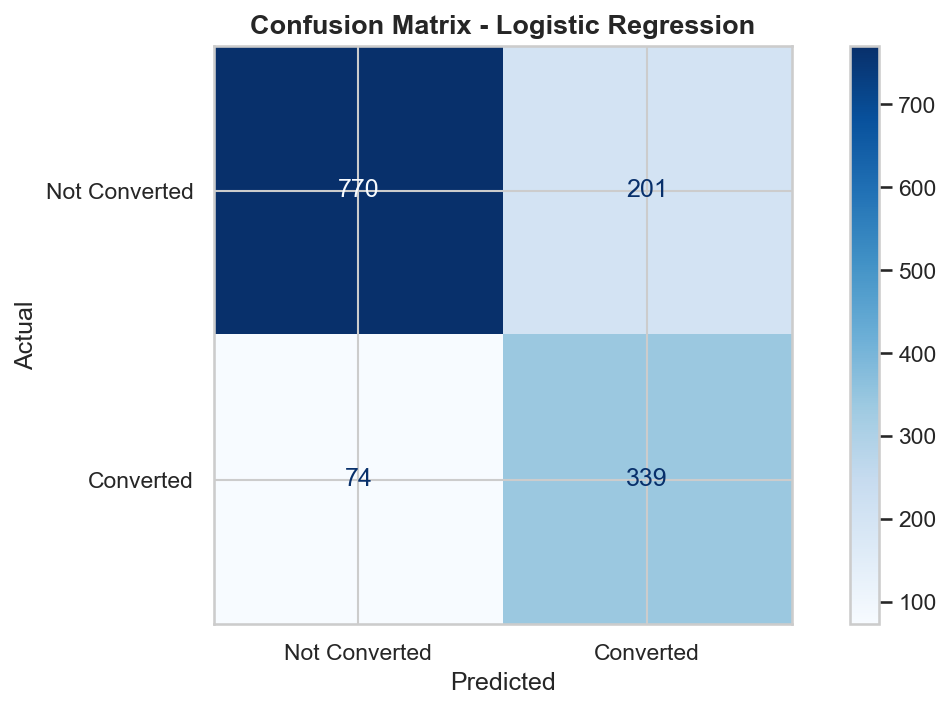

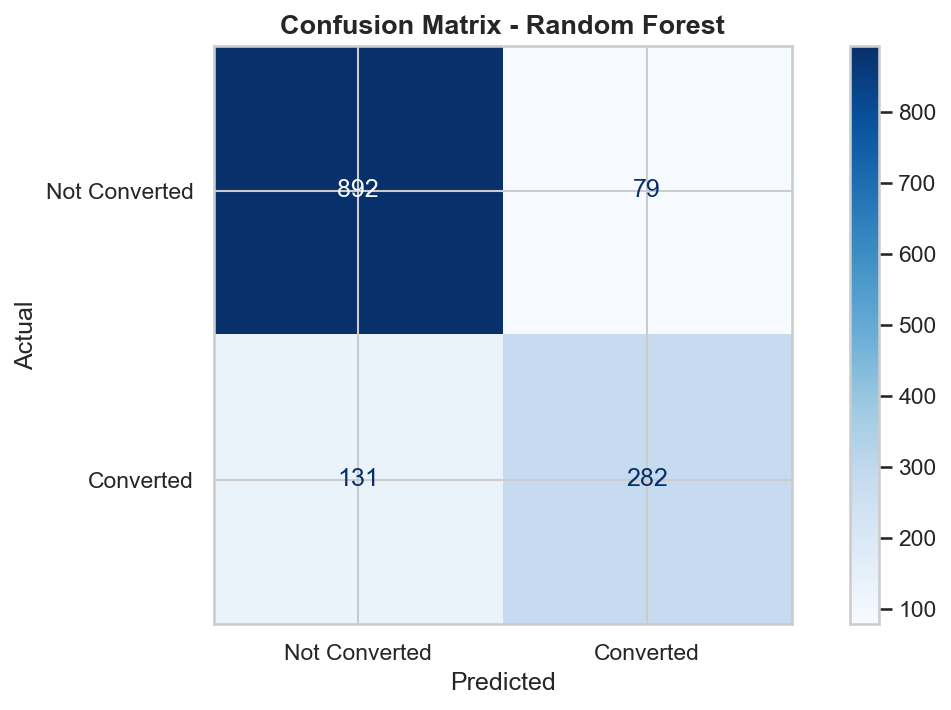

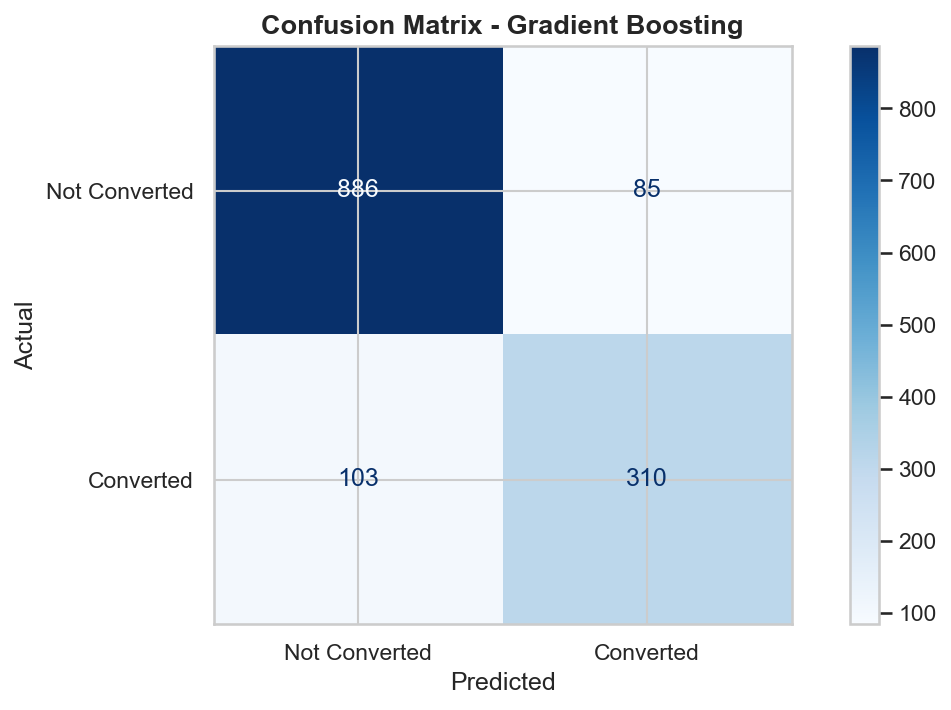

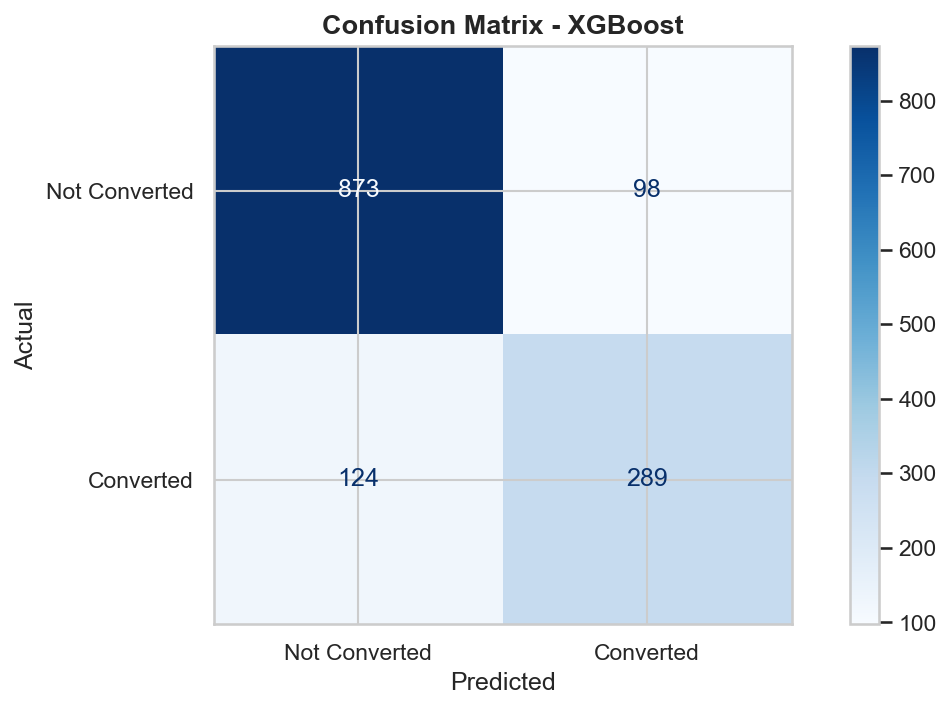

In [35]:
# Plot confusion matrices for strongest baseline models

selected_models = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
]

for model_name in selected_models:
    plot_confusion_matrix_for_model(
        model_name=model_name,
        pipeline=trained_pipelines[model_name],
        X_test=X_test_fe,
        y_test=y_test
    )

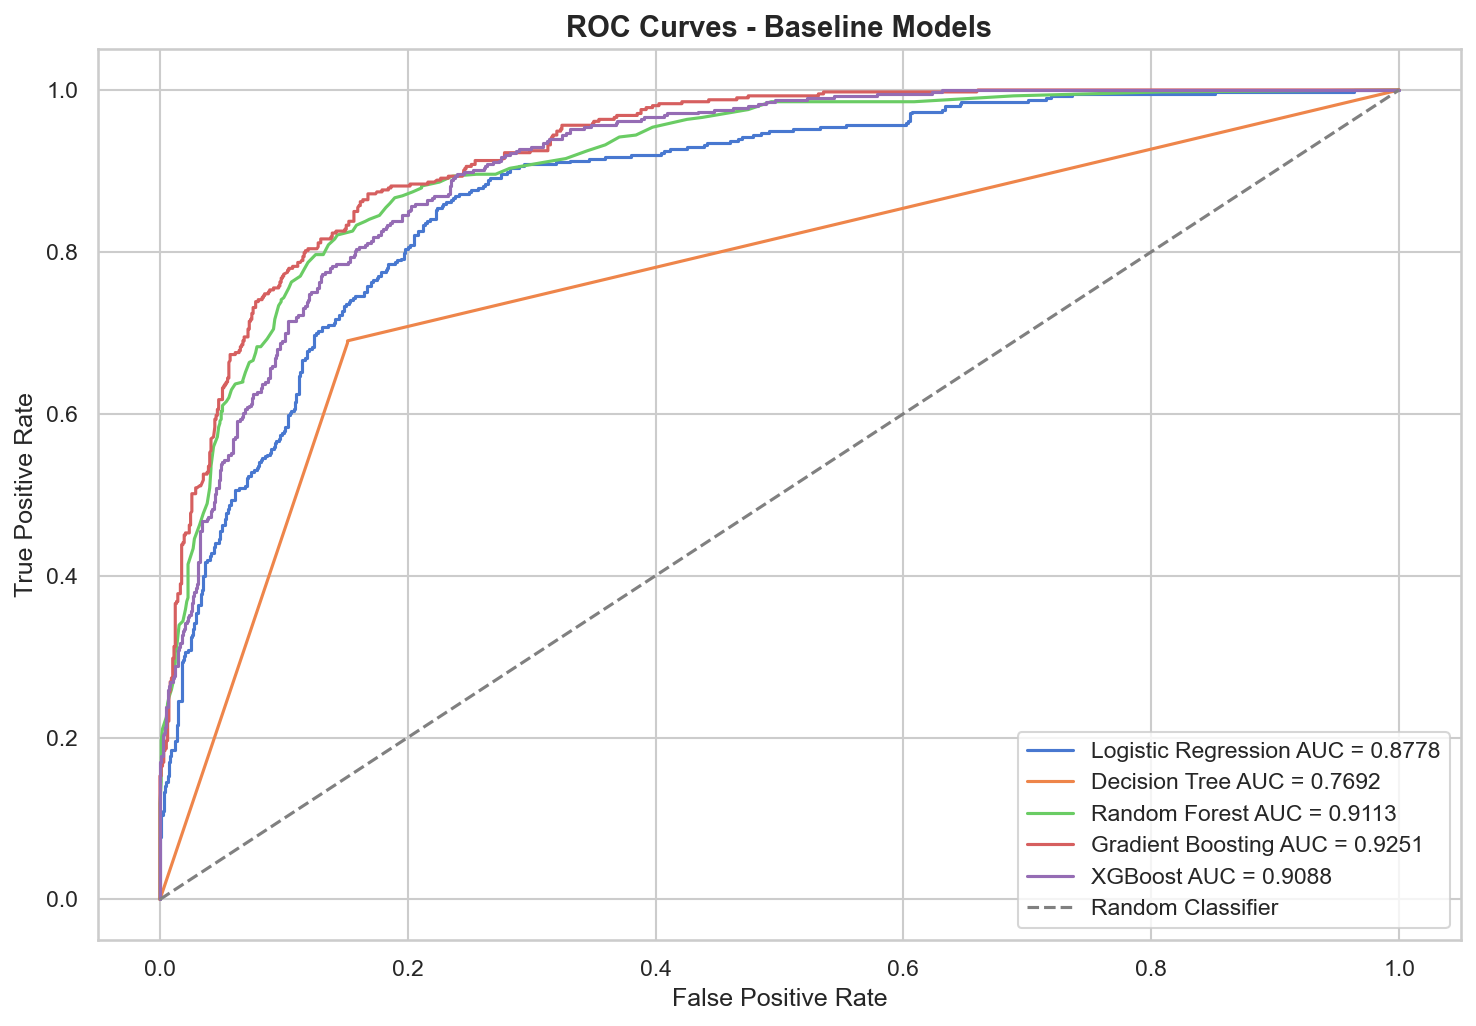

In [36]:
# Plot ROC curves for all baseline models
plt.figure(figsize=(10, 7))

for model_name, pipeline in trained_pipelines.items():
    
    y_proba = pipeline.predict_proba(X_test_fe)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    
    plt.plot(fpr, tpr, label=f"{model_name} AUC = {auc_score:.4f}")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Classifier")

plt.title("ROC Curves - Baseline Models", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

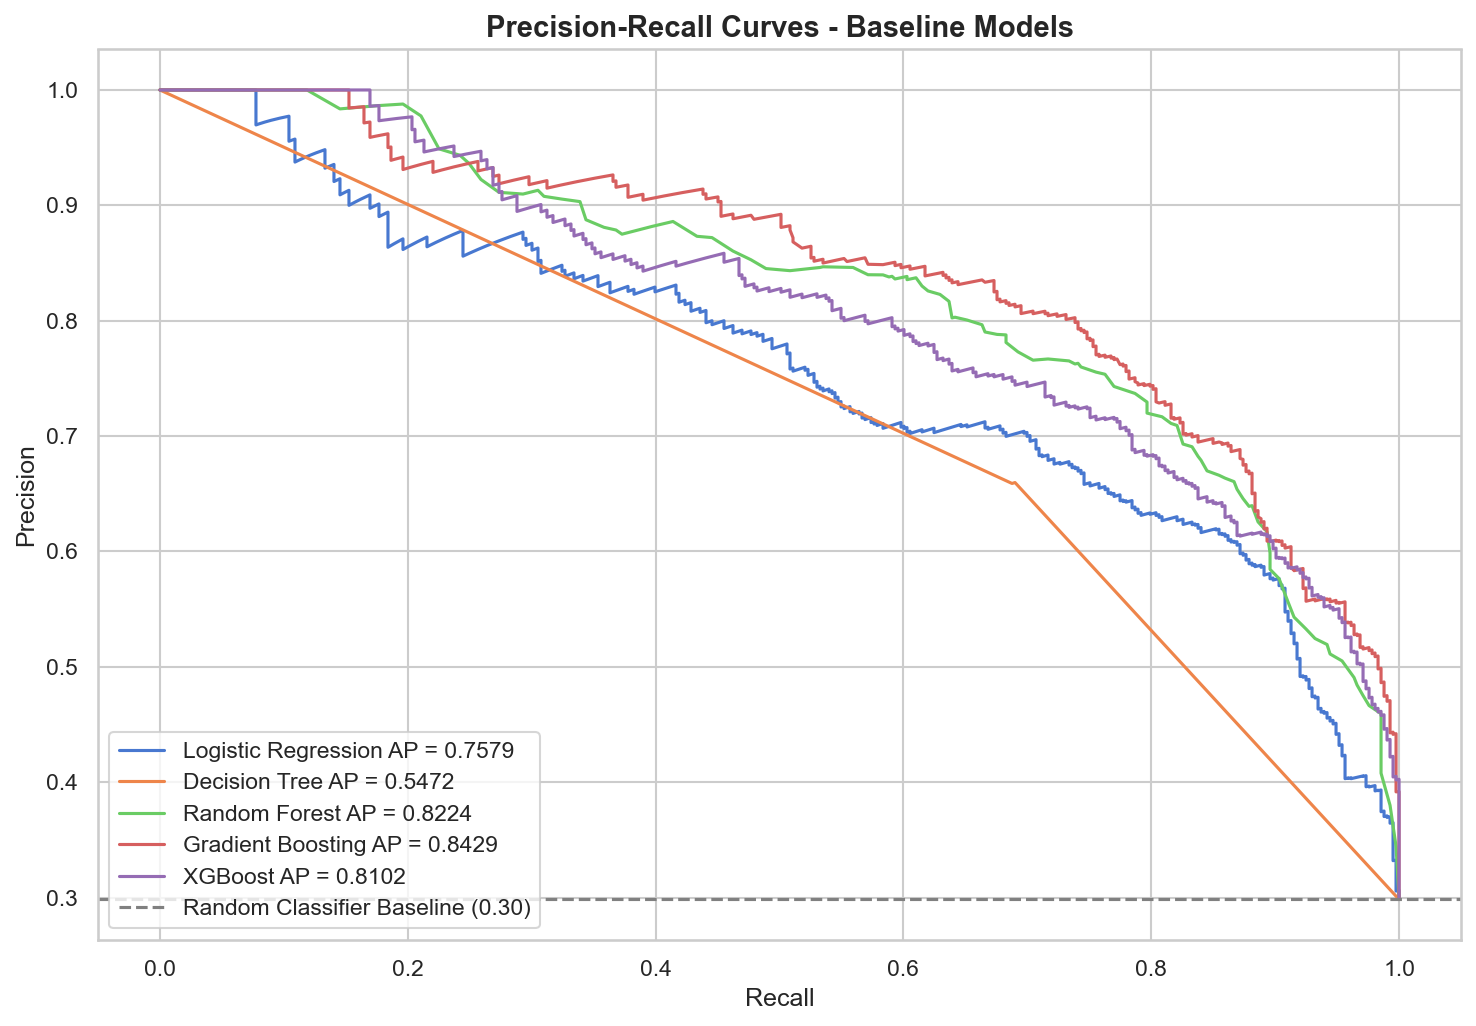

In [37]:
# Plot precision-recall curves for all baseline models
plt.figure(figsize=(10, 7))

for model_name, pipeline in trained_pipelines.items():
    
    y_proba = pipeline.predict_proba(X_test_fe)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_score = average_precision_score(y_test, y_proba)
    
    plt.plot(recall, precision, label=f"{model_name} AP = {pr_score:.4f}")

baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    color="grey",
    label=f"Random Classifier Baseline ({baseline:.2f})"
)

plt.title("Precision-Recall Curves - Baseline Models", fontsize=14, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Observations

The confusion matrices show the practical tradeoff between catching converters and avoiding false positives. For this project, the model should avoid missing too many actual converters, even if that means some additional sales follow-up.

The ROC curves compare how well each model separates converted and non-converted leads across different thresholds. Models with higher curves and higher ROC-AUC values are better at ranking leads by conversion likelihood.

The precision-recall curves are especially useful because the converted class is smaller than the non-converted class. These curves show how much precision the model keeps as recall increases, which is important when deciding how aggressively the sales team should prioritize likely converters.

#### Summary

The baseline visual review adds context behind the model comparison table and helps identify which models deserve tuning.

Next, the strongest models will be tuned before selecting the final recommendation.

---

### Tuned Gradient Boosting

Gradient Boosting was one of the stronger baseline models, so it is selected for tuning. The goal is to improve performance by testing a focused set of hyperparameters rather than running an overly large search.

The grid focuses on the main controls:

- `n_estimators`: number of boosting rounds
- `learning_rate`: how much each tree contributes
- `max_depth`: how complex each tree can become
- `subsample`: percentage of rows used for each tree

Because Gradient Boosting does not support `class_weight='balanced'` directly, sample weights are used to account for the 70/30 class imbalance.

In [38]:
# Compute sample weights for Gradient Boosting class imbalance handling
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Sample weights created for Gradient Boosting.")

Sample weights created for Gradient Boosting.


In [39]:
# Tune Gradient Boosting using a focused parameter grid
gb_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ]
)

gb_param_grid = {
    "classifier__n_estimators": [100, 300, 500],
    "classifier__learning_rate": [0.01, 0.05, 0.10],
    "classifier__max_depth": [2, 3, 4],
    "classifier__subsample": [0.8, 0.9, 1.0]
}

stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

gb_grid = GridSearchCV(
    estimator=gb_pipe,
    param_grid=gb_param_grid,
    scoring="roc_auc",
    cv=stratified_cv,
    n_jobs=-1
)

gb_grid.fit(
    X_train_fe,
    y_train,
    classifier__sample_weight=sample_weights
)

print("Best Parameters:")
print(gb_grid.best_params_)

print(f"\nBest Cross-Validation ROC-AUC: {gb_grid.best_score_:.4f}")

Best Parameters:
{'classifier__learning_rate': 0.01, 'classifier__max_depth': 4, 'classifier__n_estimators': 500, 'classifier__subsample': 0.9}

Best Cross-Validation ROC-AUC: 0.9266


In [40]:
# Evaluate tuned Gradient Boosting on the test set
best_gb_model = gb_grid.best_estimator_

y_pred_gb = best_gb_model.predict(X_test_fe)
y_proba_gb = best_gb_model.predict_proba(X_test_fe)[:, 1]

print(classification_report(y_test, y_pred_gb))

gb_results = {
    "Model": "Gradient Boosting (Tuned)",
    "Accuracy": best_gb_model.score(X_test_fe, y_test),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall": recall_score(y_test, y_pred_gb),
    "F1-Score": f1_score(y_test, y_pred_gb),
    "ROC-AUC": roc_auc_score(y_test, y_proba_gb),
    "PR-AUC": average_precision_score(y_test, y_proba_gb)
}

display(pd.DataFrame([gb_results]).round(4))

              precision    recall  f1-score   support

           0       0.93      0.85      0.89       971
           1       0.71      0.85      0.77       413

    accuracy                           0.85      1384
   macro avg       0.82      0.85      0.83      1384
weighted avg       0.86      0.85      0.85      1384



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Gradient Boosting (Tuned),0.85,0.71,0.85,0.77,0.93,0.85


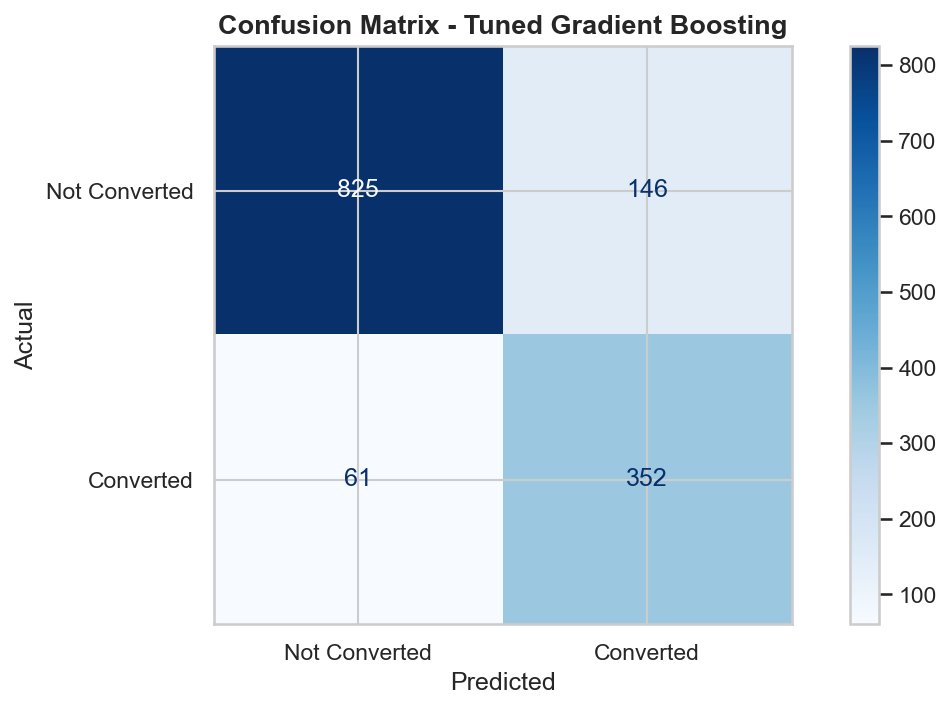

In [41]:
# Plot confusion matrix for tuned Gradient Boosting
ConfusionMatrixDisplay.from_estimator(
    best_gb_model,
    X_test_fe,
    y_test,
    display_labels=["Not Converted", "Converted"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Gradient Boosting", fontsize=13, fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### Observations

Tuned Gradient Boosting improves the recall profile compared with the baseline Gradient Boosting model while keeping overall ranking performance strong. Recall increases to **0.8523**, meaning the model catches a larger share of actual converters than the baseline version.

Precision is lower than the baseline Gradient Boosting model, which means the tuned version creates a broader follow-up list. However, the model also posts the strongest F1-Score, ROC-AUC, and PR-AUC among the candidates reviewed so far.

This makes Tuned Gradient Boosting a strong final model candidate because it balances converter capture with overall model quality.

---

### Tuned XGBoost

XGBoost is tuned next because it is usually strong on structured/tabular data and provides more control over model complexity than standard Gradient Boosting.

Instead of using a large exhaustive grid, a randomized search is used. This gives good coverage across several important hyperparameters without running an unnecessarily large number of model fits.

The search focuses on:

- `n_estimators`: number of boosting rounds
- `learning_rate`: how quickly the model learns
- `max_depth`: complexity of each tree
- `subsample`: percentage of rows used for each tree
- `colsample_bytree`: percentage of features used for each tree
- `scale_pos_weight`: class imbalance adjustment for converted leads

In [42]:
# Calculate class imbalance ratio for XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print(f"Negative class count: {negative_count}")
print(f"Positive class count: {positive_count}")
print(f"Scale pos weight: {scale_pos_weight:.4f}")

Negative class count: 2264
Positive class count: 964
Scale pos weight: 2.3485


In [43]:
# Tune XGBoost using RandomizedSearchCV
xgb_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_param_distributions = {
    "classifier__n_estimators": [100, 300, 500],
    "classifier__learning_rate": [0.01, 0.05, 0.10],
    "classifier__max_depth": [2, 3, 4],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__scale_pos_weight": [
        1,
        scale_pos_weight,
        scale_pos_weight * 1.25,
        scale_pos_weight * 1.5,
        scale_pos_weight * 2.0,
        scale_pos_weight * 2.5,
        scale_pos_weight * 3.0
    ]
}

xgb_random = RandomizedSearchCV(
    estimator=xgb_pipe,
    param_distributions=xgb_param_distributions,
    n_iter=50,
    scoring="roc_auc",
    cv=stratified_cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(X_train_fe, y_train)

print("Best Parameters:")
print(xgb_random.best_params_)

print(f"\nBest Cross-Validation ROC-AUC: {xgb_random.best_score_:.4f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters:
{'classifier__subsample': 1.0, 'classifier__scale_pos_weight': np.float64(2.3485477178423237), 'classifier__n_estimators': 300, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.7}

Best Cross-Validation ROC-AUC: 0.9277


In [44]:
# Evaluate tuned XGBoost on the test set
best_xgb_model = xgb_random.best_estimator_

y_pred_xgb = best_xgb_model.predict(X_test_fe)
y_proba_xgb = best_xgb_model.predict_proba(X_test_fe)[:, 1]

print(classification_report(y_test, y_pred_xgb))

xgb_results = {
    "Model": "XGBoost (Tuned)",
    "Accuracy": best_xgb_model.score(X_test_fe, y_test),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1-Score": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_proba_xgb),
    "PR-AUC": average_precision_score(y_test, y_proba_xgb)
}

display(pd.DataFrame([xgb_results]).round(4))

              precision    recall  f1-score   support

           0       0.94      0.83      0.88       971
           1       0.69      0.87      0.77       413

    accuracy                           0.84      1384
   macro avg       0.81      0.85      0.82      1384
weighted avg       0.86      0.84      0.85      1384



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost (Tuned),0.84,0.69,0.87,0.77,0.93,0.85


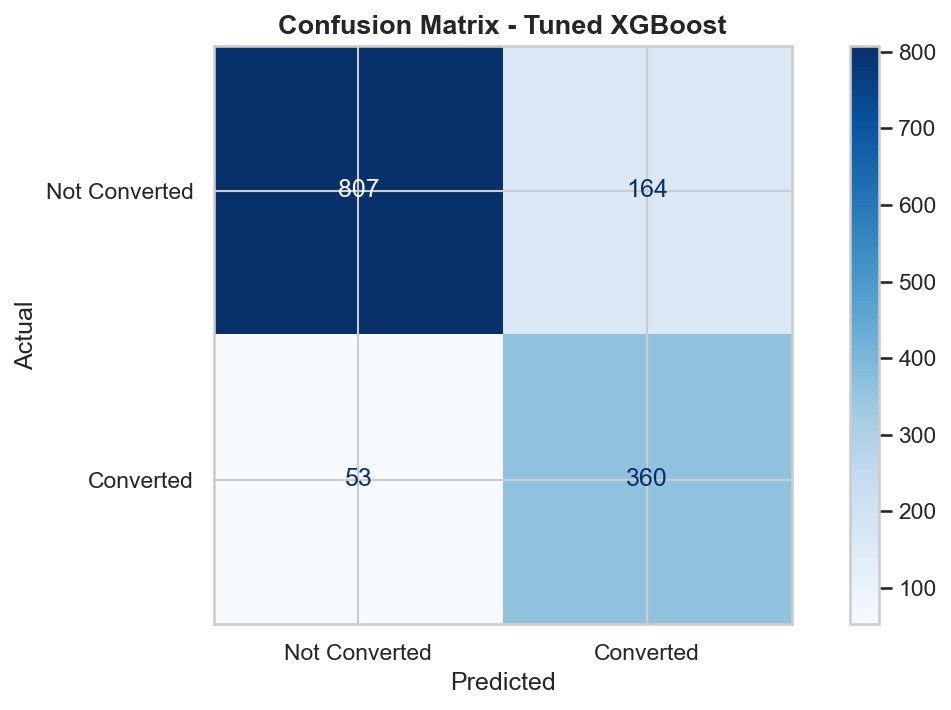

In [45]:
# Plot confusion matrix for tuned XGBoost
ConfusionMatrixDisplay.from_estimator(
    best_xgb_model,
    X_test_fe,
    y_test,
    display_labels=["Not Converted", "Converted"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned XGBoost", fontsize=13, fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### Observations

Tuned XGBoost produces the strongest recall of the models reviewed so far, with Recall at approximately **0.87**. This means it catches a very large share of actual converters, which is valuable for a lead prioritization problem.

Compared with the first tuning pass, expanding the `scale_pos_weight` range produced a more balanced challenger model. The selected value was no longer at the upper edge of the search range, which reduces concern that the class-weight search was too narrow.

The tradeoff is still precision. Precision is approximately **0.69**, which means XGBoost creates a broader follow-up list than Tuned Gradient Boosting. However, ROC-AUC and PR-AUC remain strong at approximately **0.93** and **0.85**, so the model still ranks leads well overall.

This makes Tuned XGBoost a strong challenger model, especially if the business later decides that maximizing converter capture is worth additional sales follow-up volume.

---

### Final Model Comparison

The tuned models are added to the baseline model results so all candidates can be compared in one place. The final model should not be selected from one metric alone. For this business problem, Recall, F1-Score, ROC-AUC, and PR-AUC carry the most weight because the goal is to identify likely converters while still keeping the sales list reasonably focused.

In [46]:
# Combine baseline and tuned model results

final_model_results_df = pd.concat(
    [
        model_results_df,
        pd.DataFrame([gb_results, xgb_results])
    ],
    ignore_index=True
)

# Sort by ROC-AUC for overall ranking comparison
final_model_results_df = final_model_results_df.sort_values(
    "ROC-AUC",
    ascending=False
)

display(final_model_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
5,Gradient Boosting (Tuned),0.85,0.71,0.85,0.77,0.93,0.85
6,XGBoost (Tuned),0.84,0.69,0.87,0.77,0.93,0.85
0,Gradient Boosting,0.86,0.78,0.75,0.77,0.93,0.84
1,Random Forest,0.85,0.78,0.68,0.73,0.91,0.82
2,XGBoost,0.84,0.75,0.70,0.72,0.91,0.81
3,Logistic Regression,0.80,0.63,0.82,0.71,0.88,0.76
4,Decision Tree,0.80,0.66,0.69,0.67,0.77,0.55


In [47]:
# Highlight the best score for each metric
final_model_results_df.style.highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"],
    axis=0,
    props="background-color: #c6efce; color: #1a5c2e; font-weight: bold"
).format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}"
})

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
5,Gradient Boosting (Tuned),0.8504,0.7068,0.8523,0.7728,0.9294,0.8535
6,XGBoost (Tuned),0.8432,0.6870,0.8717,0.7684,0.9282,0.8520
0,Gradient Boosting,0.8642,0.7848,0.7506,0.7673,0.9251,0.8429
1,Random Forest,0.8483,0.7812,0.6828,0.7287,0.9113,0.8224
2,XGBoost,0.8396,0.7468,0.6998,0.7225,0.9088,0.8102
3,Logistic Regression,0.8013,0.6278,0.8208,0.7114,0.8778,0.7579
4,Decision Tree,0.8013,0.6597,0.6901,0.6746,0.7692,0.5472


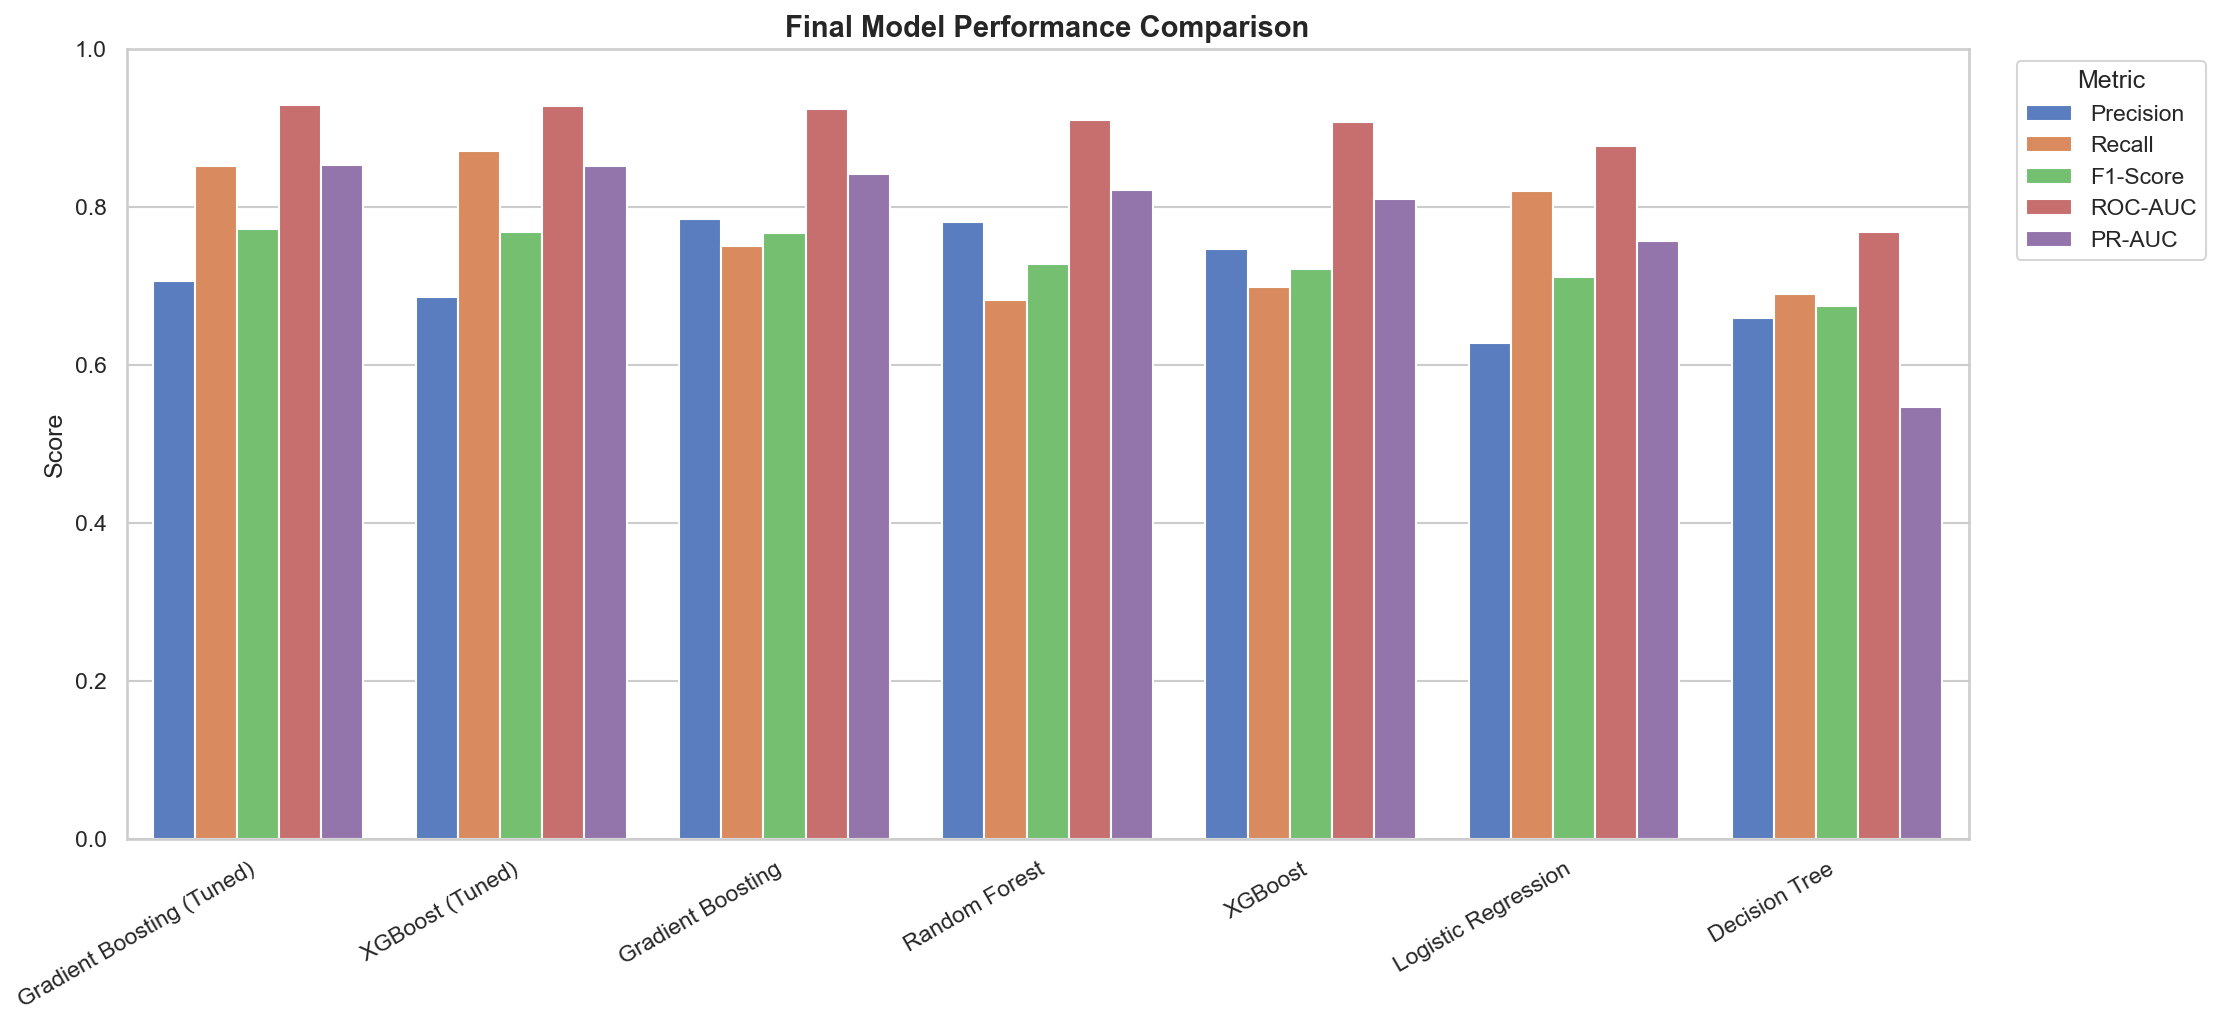

In [48]:
# Visualize final model comparison across key metrics
metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]

final_results_long = final_model_results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(15, 7))

ax = sns.barplot(
    data=final_results_long,
    x="Model",
    y="Score",
    hue="Metric"
)

ax.set_title("Final Model Performance Comparison", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Observations

The final comparison shows that the strongest models are the ensemble methods, especially the Gradient Boosting models and Tuned XGBoost.

The main decision is the tradeoff between recall and precision. Tuned XGBoost has the highest recall, which means it catches the largest share of actual converters. Tuned Gradient Boosting has slightly lower recall, but stronger precision and slightly stronger overall balance across F1-Score, ROC-AUC, and PR-AUC.

For this project, recall is important because the business wants to catch as many likely converters as possible. However, precision and PR-AUC still matter because the sales list needs to remain focused. A model that catches more converters but creates too much extra follow-up volume may not scale well operationally.

The final model should therefore be selected based on the best business tradeoff, not a single metric.

---

### Final Model Visual Review

The final comparison table summarizes the metrics, but ROC and precision-recall curves show how the strongest models behave across different thresholds.

This is useful because the final business decision is not just whether a model predicts `0` or `1`, but how well it ranks leads by conversion likelihood.

In [49]:
# Build final model dictionary for visual comparison
final_models = {
    **trained_pipelines,
    "Gradient Boosting (Tuned)": best_gb_model,
    "XGBoost (Tuned)": best_xgb_model
}

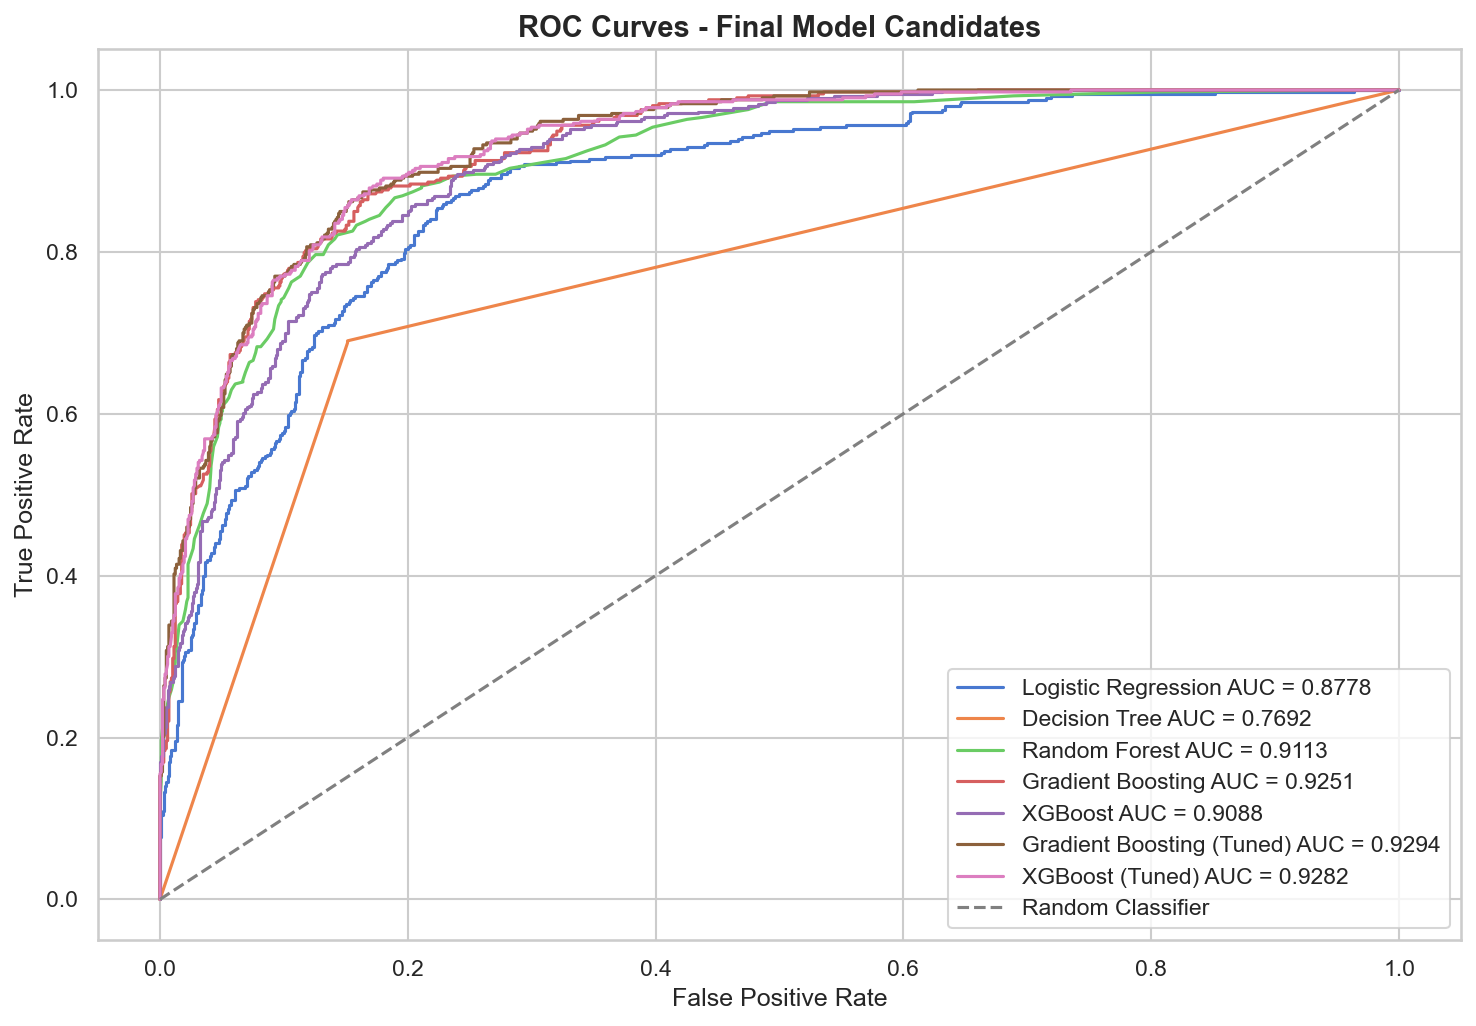

In [50]:
# Plot ROC curves for final model candidates

plt.figure(figsize=(10, 7))

for model_name, model in final_models.items():
    
    y_proba = model.predict_proba(X_test_fe)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    
    plt.plot(fpr, tpr, label=f"{model_name} AUC = {auc_score:.4f}")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Classifier")

plt.title("ROC Curves - Final Model Candidates", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

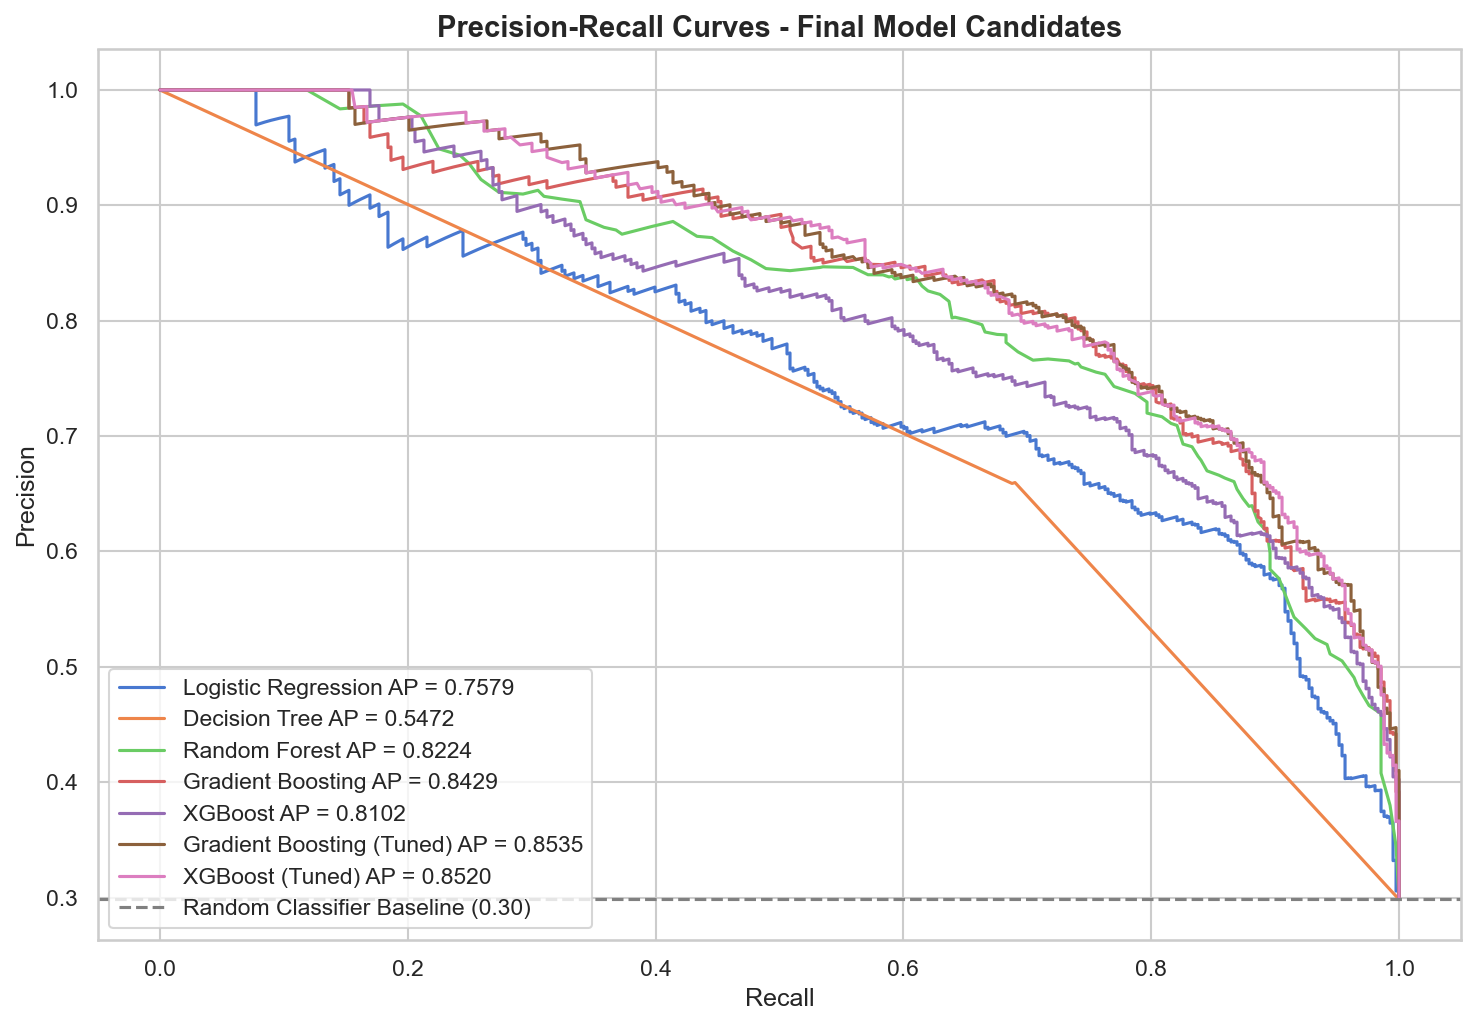

In [51]:
# Plot precision-recall curves for final model candidates
plt.figure(figsize=(10, 7))

for model_name, model in final_models.items():
    
    y_proba = model.predict_proba(X_test_fe)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_score = average_precision_score(y_test, y_proba)
    
    plt.plot(recall, precision, label=f"{model_name} AP = {pr_score:.4f}")

baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    color="grey",
    label=f"Random Classifier Baseline ({baseline:.2f})"
)

plt.title("Precision-Recall Curves - Final Model Candidates", fontsize=14, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Observations

The ROC curves show how well each model separates converted and non-converted leads across different thresholds. The stronger models should sit above the weaker models for most of the curve.

The precision-recall curves are especially important for this project because converted leads are the smaller class. These curves show how much precision each model maintains as recall increases.

For lead prioritization, the best model is not necessarily the one with the highest accuracy. The final choice should favor a model that ranks leads well, captures a high share of likely converters, and still produces a sales list that is focused enough to be useful.

---

### Metric Leaders by Category

Before selecting a final model, the strongest model for each key metric is reviewed. This helps separate individual metric winners from the best overall business recommendation.

In [52]:
# Review top model candidates by key metrics

key_metrics = ["Recall", "F1-Score", "ROC-AUC", "PR-AUC", "Precision"]

top_by_metric = {}

for metric in key_metrics:
    best_row = final_model_results_df.loc[final_model_results_df[metric].idxmax()]
    top_by_metric[metric] = {
        "Best Model": best_row["Model"],
        "Score": best_row[metric]
    }

top_by_metric_df = pd.DataFrame(top_by_metric).T

display(top_by_metric_df)

,Best Model,Score
Recall,XGBoost (Tuned),0.87
F1-Score,Gradient Boosting (Tuned),0.77
ROC-AUC,Gradient Boosting (Tuned),0.93
PR-AUC,Gradient Boosting (Tuned),0.85
Precision,Gradient Boosting,0.78


#### Summary

No single model leads every metric. Tuned XGBoost has the strongest recall, while Tuned Gradient Boosting leads on F1-Score, ROC-AUC, and PR-AUC. The baseline Gradient Boosting model has the highest precision, but it gives up recall compared with the tuned models.

Because this project is focused on lead prioritization, the final recommendation should balance converter capture, ranking quality, and sales-list focus. Tuned Gradient Boosting remains the best overall recommendation because it preserves strong recall while keeping the follow-up list slightly more focused than the recall-oriented XGBoost challenger.

---

#### Recommended Final Model

**Tuned Gradient Boosting**

Tuned Gradient Boosting is recommended as the final model because it provides the strongest overall balance across the key metrics. It captures a high share of actual converters with Recall of approximately **0.85**, while maintaining slightly stronger Precision, F1-Score, ROC-AUC, and PR-AUC than Tuned XGBoost.

Tuned XGBoost has the highest Recall at approximately **0.87**, which means it catches the most converters. However, Tuned Gradient Boosting has stronger Precision and slightly stronger overall ranking performance, making it the safer model to use as the primary recommendation.

From a business standpoint, Tuned Gradient Boosting is the better model to scale. It still prioritizes converter capture, but it does not lean as aggressively into recall as XGBoost. This helps keep the sales follow-up list more focused while still identifying most likely converters.

#### Challenger Model

**Tuned XGBoost** should be kept as a challenger model. It captures the largest share of actual converters and remains a strong option if ExtraaLearn later decides that maximizing recall is more important than keeping the follow-up list slightly cleaner.

For now, Tuned Gradient Boosting will be used for the remaining sections of the project, including explainability, lead scoring, and priority tier creation.

#### Modeling Summary

Tuned Gradient Boosting is selected as the recommended final model for the rest of the project. It provides strong converter capture, strong ranking performance, and a more scalable sales follow-up list than the more recall-heavy XGBoost challenger.

The next section moves from model performance to model explanation: which features are driving the predictions and how those drivers translate into business actions.

---

## Feature Importance & Explainability

The final model shows strong performance, but model performance alone is not enough. The next step is to understand which features are driving the predictions and how those drivers translate into business insight.

This section uses SHAP values to explain the recommended final model, Tuned Gradient Boosting. SHAP helps show which features push predictions toward conversion and which features push predictions away from conversion.

The goal is to connect the model results back to the business question: what separates likely converters from everyone else?

In [53]:
# Prepare final model and transformed test data for SHAP explainability

# Pull the fitted preprocessing step and classifier from the final model pipeline
final_preprocessor = best_gb_model.named_steps["preprocessor"]
final_classifier = best_gb_model.named_steps["classifier"]

# Transform the test data using the fitted preprocessor
X_test_transformed = final_preprocessor.transform(X_test_fe)

# Convert to dense array if preprocessing returns a sparse matrix
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get feature names after scaling and one-hot encoding
feature_names = final_preprocessor.get_feature_names_out()

# Clean feature names for easier reading
clean_feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
]

# Create DataFrame for SHAP
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=clean_feature_names,
    index=X_test_fe.index
)

print(f"Transformed test data shape: {X_test_transformed_df.shape}")
display(X_test_transformed_df.head())

Transformed test data shape: (1384, 23)


,age,website_visits,time_spent_on_website,page_views_per_visit,print_media_type1,print_media_type2,digital_media,educational_channels,referral,marketing_touch_count,engagement_score,high_intent_flag,current_occupation_Professional,current_occupation_Student,current_occupation_Unemployed,first_interaction_Mobile App,first_interaction_Website,profile_completed_High,profile_completed_Low,profile_completed_Medium,last_activity_Email Activity,last_activity_Phone Activity,last_activity_Website Activity
515,-0.26,-1.02,-0.70,-1.65,-0.35,-0.24,-0.36,-0.42,-0.15,-0.69,-1.79,-0.59,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00
4313,0.81,-0.61,-0.96,-0.44,-0.35,-0.24,-0.36,-0.42,-0.15,-0.69,-1.10,-0.59,0.00,0.00,1.00,1.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00
1286,-1.72,1.45,-0.50,0.53,2.86,-0.24,-0.36,2.36,-0.15,2.52,0.72,-0.59,0.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00
3375,0.97,-0.61,0.52,-1.78,-0.35,-0.24,-0.36,2.36,-0.15,0.92,-0.93,1.70,0.00,0.00,1.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00
186,0.97,-0.20,-0.73,0.76,2.86,-0.24,-0.36,-0.42,-0.15,0.92,-0.13,-0.59,1.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00


### SHAP Value Calculation

SHAP values are calculated on the transformed test data. This allows the explanation to match the exact feature representation used by the final model, including scaled numeric features and one-hot encoded categorical features.

In [54]:
# Create SHAP explainer for the final Gradient Boosting model

explainer = shap.TreeExplainer(final_classifier)

# Calculate SHAP values for the transformed test data
shap_values = explainer.shap_values(X_test_transformed_df)

# Confirm SHAP output shape
print(f"SHAP values shape: {shap_values.shape}")
print(f"Transformed test data shape: {X_test_transformed_df.shape}")

SHAP values shape: (1384, 23)
Transformed test data shape: (1384, 23)


#### Summary

SHAP values were calculated for the final Tuned Gradient Boosting model. Each value represents how much a feature pushes a prediction toward conversion or away from conversion for a specific lead.

### Global SHAP Feature Importance

The first SHAP view summarizes which features have the largest overall impact on model predictions. This does not show whether a feature increases or decreases conversion likelihood; it shows which features matter most to the model across all test records.

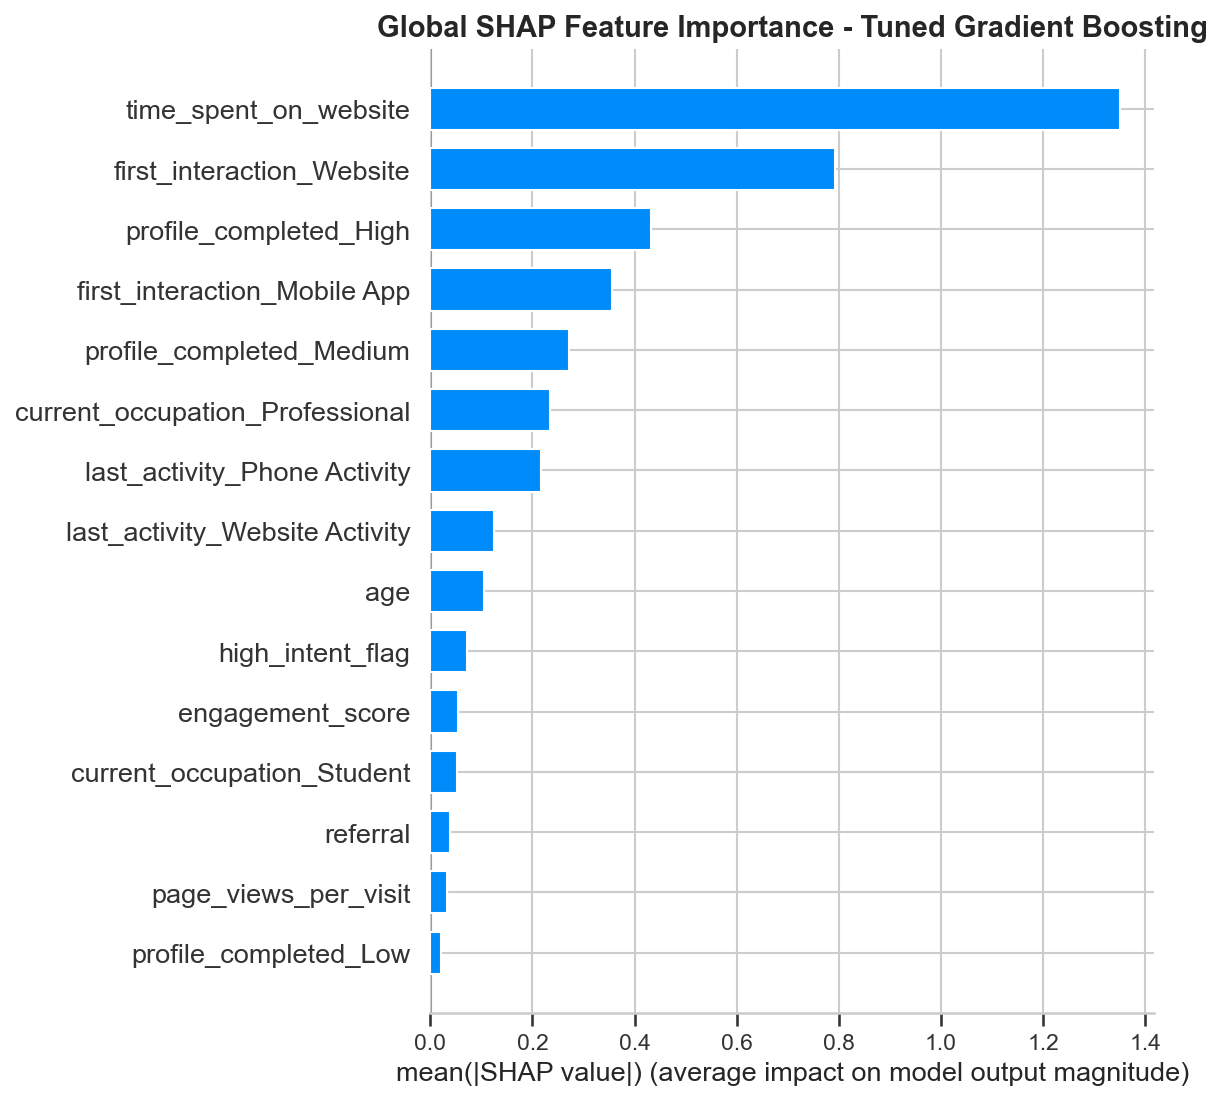

In [55]:
# Plot global SHAP feature importance

shap.summary_plot(
    shap_values,
    X_test_transformed_df,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title(
    "Global SHAP Feature Importance - Tuned Gradient Boosting",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Observations

The global SHAP feature importance chart shows that website engagement and lead-entry behavior are the strongest drivers in the final model.

`time_spent_on_website` is the most important feature overall, which reinforces the EDA finding that time spent on the site is one of the clearest behavioral signals of conversion intent.

The next strongest features are `first_interaction_Website` and `first_interaction_Mobile App`, showing that the lead’s first entry channel plays a major role in the model’s predictions. Profile completion also ranks highly, especially `profile_completed_High` and `profile_completed_Medium`, which suggests that profile completeness is an important signal in the model.

This chart shows which features matter most, but it does not show direction. The next SHAP view will help show whether higher or lower values push predictions toward conversion or away from conversion.

---

### SHAP Beeswarm Plot

The SHAP beeswarm plot shows both feature importance and direction. Each dot represents one lead in the test set.

Features higher on the chart have a larger impact on model predictions. Dots farther to the right push the model toward predicting conversion, while dots farther to the left push the model away from conversion.

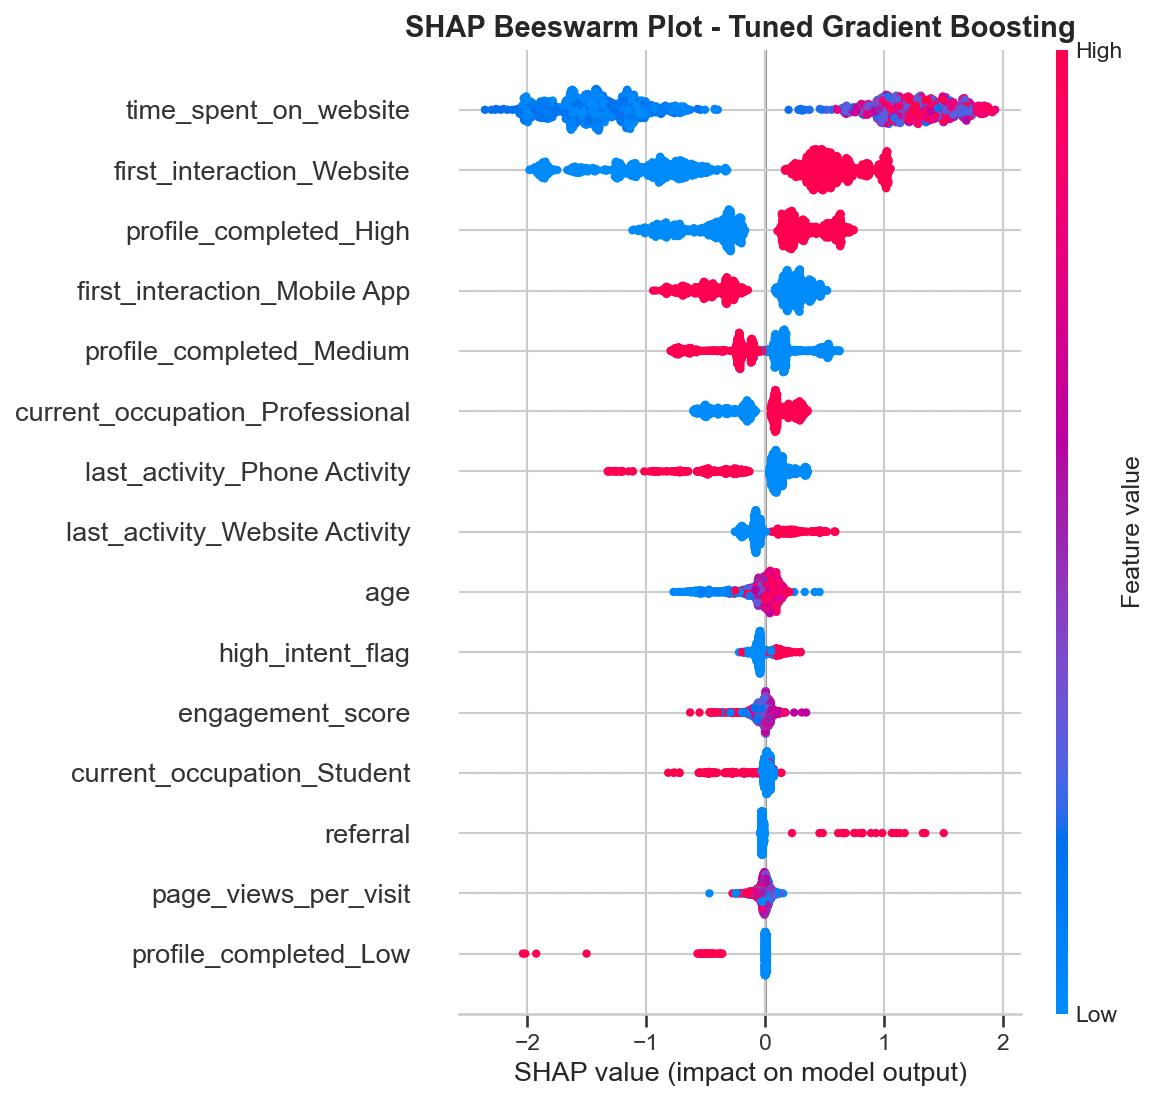

In [56]:
# Plot SHAP beeswarm to show feature direction and impact

shap.summary_plot(
    shap_values,
    X_test_transformed_df,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Beeswarm Plot - Tuned Gradient Boosting",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Observations

The SHAP beeswarm plot shows both the strength and direction of the model’s strongest drivers.

`time_spent_on_website` is the clearest behavioral signal. Higher values push predictions toward conversion, while lower values push predictions away from conversion. This confirms the earlier EDA finding that time spent on the website is one of the strongest indicators of lead intent.

The first interaction channel also matters. `first_interaction_Website` pushes predictions toward conversion, while `first_interaction_Mobile App` generally pushes predictions away from conversion. This suggests that website-first leads behave more like high-conversion leads than mobile-app-first leads.

Profile completion follows the same pattern. `profile_completed_High` pushes predictions toward conversion, while `profile_completed_Medium` and `profile_completed_Low` tend to push predictions away from conversion. This supports the idea that profile completeness is a meaningful commitment signal.

Recent activity also adds useful context. `last_activity_Website Activity` tends to push predictions toward conversion, while `last_activity_Phone Activity` tends to push predictions away. This suggests that recent self-directed website behavior is more predictive than phone activity alone.

The strongest SHAP drivers are website engagement, first interaction channel, and profile completion. These are business-friendly signals that can be translated directly into lead prioritization rules and sales actions.

*Note: For one-hot encoded categorical features, high values mean that category is present. For example, a high value for `first_interaction_Website` means the lead’s first interaction was through the website.*

---

### SHAP Importance Table

To make the SHAP results easier to review, the average absolute SHAP value is calculated for each feature. This provides a ranked table of the features with the largest overall impact on model predictions.

In [57]:
# Create a SHAP feature importance table

shap_importance_df = pd.DataFrame({
    "Feature": X_test_transformed_df.columns,
    "Mean Absolute SHAP Value": np.abs(shap_values).mean(axis=0)
})

shap_importance_df = shap_importance_df.sort_values(
    "Mean Absolute SHAP Value",
    ascending=False
)

display(shap_importance_df.head(15).round(4))

,Feature,Mean Absolute SHAP Value
2,time_spent_on_website,1.35
16,first_interaction_Website,0.79
17,profile_completed_High,0.43
15,first_interaction_Mobile App,0.36
19,profile_completed_Medium,0.27
12,current_occupation_Professional,0.23
21,last_activity_Phone Activity,0.22
22,last_activity_Website Activity,0.13
0,age,0.11
11,high_intent_flag,0.07


#### Summary

The SHAP importance table confirms the same pattern shown in the SHAP visuals. Website engagement, first interaction channel, and profile completion are the strongest drivers of the final model’s predictions.

---

### Engineered Feature Reflection

The engineered features were useful for testing business logic, but they added limited marginal signal in the final model.

In the SHAP importance table, `high_intent_flag` and `engagement_score` ranked much lower than the strongest raw behavioral features, and `marketing_touch_count` did not appear in the top 15 features. This suggests that the model was already capturing most of the useful signal directly from the original variables, especially `time_spent_on_website`.

This is still a useful finding. The engineered features helped translate engagement and intent into business-friendly concepts, but the final model relied more heavily on the raw signals themselves. For future scoring or business rules, these engineered features may still be helpful for communication and interpretation, even if they did not materially drive model performance in this version.

---

### Business Interpretation of SHAP Results

The SHAP results show that the model is not relying on random or hard-to-explain signals. The strongest drivers are tied directly to lead behavior and engagement.

#### Key Takeaways

**1. Website engagement is the strongest conversion signal.**  
`time_spent_on_website` is the most important feature in the final model. Leads who spend more time on the website are more likely to be scored as potential converters. This suggests that meaningful website engagement is a strong sign of buying intent.

**2. Website-first leads behave differently from mobile-app-first leads.**  
The model gives strong importance to both `first_interaction_Website` and `first_interaction_Mobile App`. Website-first leads are more likely to be pushed toward conversion, while mobile-app-first leads are generally pushed away from conversion. This may suggest that leads who begin on the website are doing more intentional program research.

**3. Profile completion is a major commitment signal.**  
`profile_completed_High` pushes predictions toward conversion, while lower completion levels tend to push predictions away. This supports the idea that leads who complete more of their profile are showing stronger intent.

**4. Recent website activity matters.**  
`last_activity_Website Activity` tends to push predictions toward conversion, while phone activity tends to push predictions away. This suggests that recent self-directed website behavior may be a stronger signal than follow-up activity alone.

#### Explainability Summary

The explainability results support the model’s business logic. The final model is primarily driven by website engagement, first interaction channel, profile completion, and recent website activity.

These drivers are understandable and actionable. Sales and marketing teams can use them to prioritize leads who show stronger buying intent, while also identifying lower-intent patterns that may need nurturing rather than immediate sales outreach.

---

## Lead Scoring & Priority Tiers

The final model can now be used to score leads based on their predicted probability of conversion. These scores turn the classification model into a practical sales tool.

Instead of only predicting whether a lead will convert or not, the model assigns each lead a probability score. Higher scores indicate stronger conversion likelihood and can be used to prioritize sales outreach.

In [58]:
# Generate predicted conversion probabilities using the final model

lead_scores = pd.DataFrame({
    "ID": lead_ids_test,
    "Actual Status": y_test,
    "Conversion Probability": best_gb_model.predict_proba(X_test_fe)[:, 1]
})

# Sort leads from highest to lowest predicted conversion probability
lead_scores = lead_scores.sort_values(
    "Conversion Probability",
    ascending=False
)

display(lead_scores.head(10))

,ID,Actual Status,Conversion Probability
2706,EXT2707,1,0.96
3703,EXT3704,1,0.96
3663,EXT3664,1,0.96
2275,EXT2276,1,0.96
3672,EXT3673,1,0.96
168,EXT169,1,0.96
555,EXT556,1,0.96
943,EXT944,1,0.96
2105,EXT2106,1,0.96
4469,EXT4470,1,0.96


In [59]:
# Review distribution of predicted conversion probabilities

display(lead_scores["Conversion Probability"].describe().round(4))

count   1384.00
mean       0.38
std        0.35
min        0.02
25%        0.03
50%        0.31
75%        0.76
max        0.96
Name: Conversion Probability, dtype: float64

#### Summary

Each lead in the test set now has a predicted conversion probability from the final Tuned Gradient Boosting model. These probabilities can be used to rank leads from highest to lowest priority before converting them into practical sales outreach tiers.

---

### Lead Priority Tiers

The conversion probabilities are converted into priority tiers so the model output can be used by the sales team.

The tiers are designed to separate leads into practical outreach groups:

- **High Priority:** strongest conversion likelihood
- **Medium Priority:** possible converters who may need additional follow-up
- **Low Priority:** lower conversion likelihood, better suited for nurture campaigns

The cutoff values are based on the distribution of predicted probabilities and the overall conversion rate. The **High Priority** cutoff of `0.75` is close to the 75th percentile of predicted probabilities, which separates the strongest lead group. The **Medium Priority** cutoff of `0.35` is set slightly above the overall conversion rate of about 30%, so medium-priority leads still represent above-baseline conversion potential. Leads below that threshold are treated as lower priority because their predicted probability is closer to or below the general population rate.

In [60]:
# Create lead priority tiers based on predicted conversion probability

def assign_priority_tier(probability):
    if probability >= 0.75:
        return "High Priority"
    elif probability >= 0.35:
        return "Medium Priority"
    else:
        return "Low Priority"

lead_scores["Priority Tier"] = lead_scores["Conversion Probability"].apply(assign_priority_tier)

display(lead_scores.head(10))

,ID,Actual Status,Conversion Probability,Priority Tier
2706,EXT2707,1,0.96,High Priority
3703,EXT3704,1,0.96,High Priority
3663,EXT3664,1,0.96,High Priority
2275,EXT2276,1,0.96,High Priority
3672,EXT3673,1,0.96,High Priority
168,EXT169,1,0.96,High Priority
555,EXT556,1,0.96,High Priority
943,EXT944,1,0.96,High Priority
2105,EXT2106,1,0.96,High Priority
4469,EXT4470,1,0.96,High Priority


In [61]:
# Review tier distribution and conversion rate by priority tier

tier_summary = (
    lead_scores
    .groupby("Priority Tier")
    .agg(
        Lead_Count=("ID", "count"),
        Actual_Conversion_Rate=("Actual Status", "mean"),
        Avg_Predicted_Probability=("Conversion Probability", "mean")
    )
    .reset_index()
)

# Sort tiers in business priority order
tier_order = ["High Priority", "Medium Priority", "Low Priority"]
tier_summary["Priority Tier"] = pd.Categorical(
    tier_summary["Priority Tier"],
    categories=tier_order,
    ordered=True
)

tier_summary = tier_summary.sort_values("Priority Tier")

display(tier_summary.round(4))

,Priority Tier,Lead_Count,Actual_Conversion_Rate,Avg_Predicted_Probability
0,High Priority,353,0.82,0.87
2,Medium Priority,267,0.33,0.53
1,Low Priority,764,0.05,0.10


### Priority Tier Capture Rate

In addition to reviewing conversion rates by tier, it is useful to measure how many actual converters are captured in the high-priority group. This helps show whether the model is concentrating future customers into a smaller, more actionable sales list.

In [62]:
# Review how many actual converters are captured in the High Priority tier

high_priority_mask = lead_scores["Priority Tier"] == "High Priority"

high_priority_leads = high_priority_mask.sum()
total_leads = len(lead_scores)

high_priority_converters = lead_scores.loc[high_priority_mask, "Actual Status"].sum()
total_converters = lead_scores["Actual Status"].sum()

high_priority_lead_share = high_priority_leads / total_leads
high_priority_capture_rate = high_priority_converters / total_converters

print(
    f"High Priority leads: {high_priority_leads} of {total_leads} "
    f"({high_priority_lead_share * 100:.1f}% of leads)"
)

print(
    f"Converters captured in High Priority: {high_priority_converters} of {total_converters} "
    f"({high_priority_capture_rate * 100:.1f}% of converters)"
)

High Priority leads: 353 of 1384 (25.5% of leads)
Converters captured in High Priority: 288 of 413 (69.7% of converters)


#### Summary

The High Priority tier contains **353 of 1,384 leads**, or **25.5%** of the test-set lead pool. Within that smaller group, the model captures **288 of 413 actual converters**, or **69.7%** of all converters in the test set.

This is one of the strongest business outcomes from the model. By focusing first on roughly one-quarter of the lead pool, the sales team can reach nearly 70% of the leads who eventually converted.

#### Observations

The priority tiers separate leads into clearly different conversion groups.

The **High Priority** tier contains 353 leads and has an actual conversion rate of **82%**, compared with the overall test-set conversion rate of about 30%. This is the strongest sales outreach group and should receive the fastest follow-up.

The **Medium Priority** tier contains 267 leads with an actual conversion rate of **33%**. This group is close to the overall conversion rate, so these leads may still be worth follow-up, but they are less urgent than the high-priority group.

The **Low Priority** tier contains the largest group of leads, 764 total, but has an actual conversion rate of only **5%**. These leads are better suited for automated nurture campaigns or lower-cost follow-up rather than immediate sales outreach.

The priority tiers translate the model output into a practical sales workflow: call the highest-probability leads first, continue nurturing medium-priority leads, and avoid over-investing manual sales effort in the lowest-probability group.

### Priority Tier Visualization

The tier summary is visualized to show how conversion rates differ across the recommended sales priority groups.

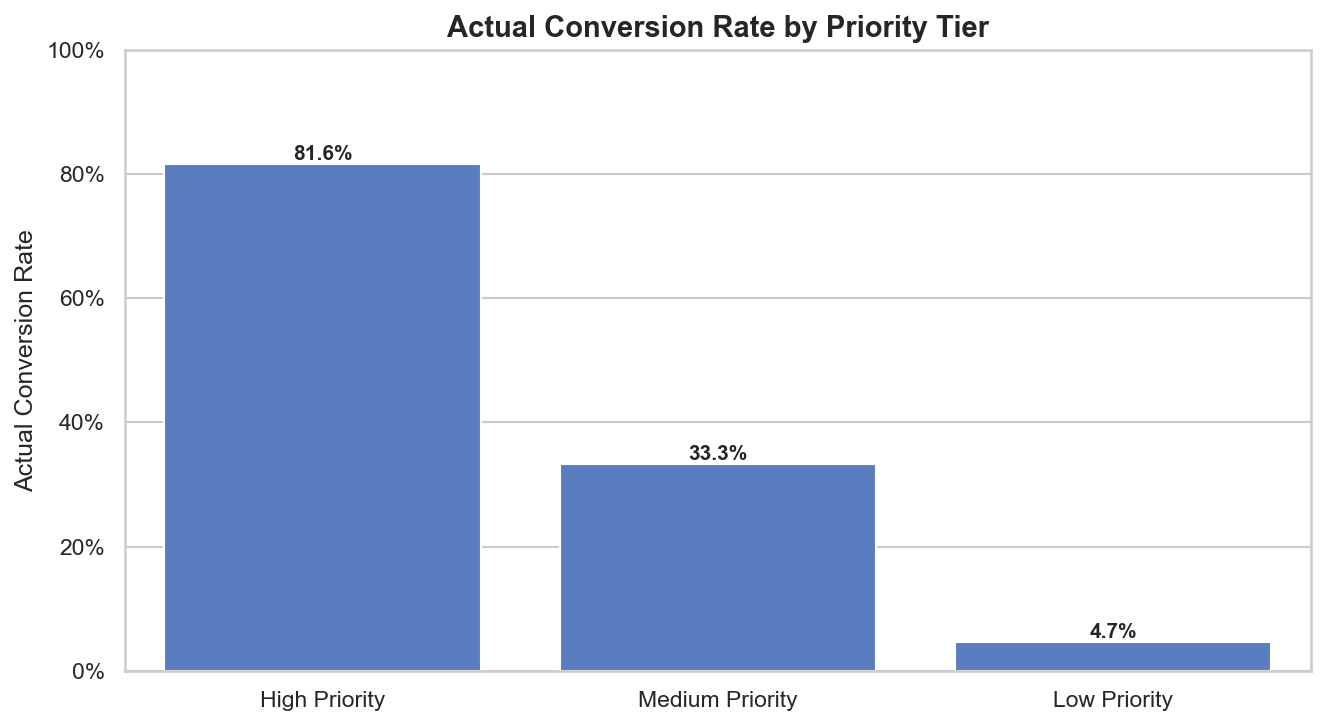

In [63]:
# Visualize actual conversion rate by priority tier

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=tier_summary,
    x="Priority Tier",
    y="Actual_Conversion_Rate",
    order=["High Priority", "Medium Priority", "Low Priority"]
)

ax.set_title("Actual Conversion Rate by Priority Tier", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Actual Conversion Rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)

# Add percentage labels
for p in ax.patches:
    ax.annotate(
        f"{p.get_height() * 100:.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

#### Summary

The visualization confirms that the model-based tiers create meaningful separation. High-priority leads convert at a much higher rate than medium- and low-priority leads, making this tiering approach useful for sales prioritization.

---

### Export Scored Lead List

The final scored lead list is prepared as a practical output from the model. Each lead receives a predicted conversion probability and a priority tier that can be used for sales follow-up planning.

In [64]:
# Create final scored lead list for review/export

scored_leads_export = lead_scores.copy()

# Format probability for easier business review
scored_leads_export["Conversion Probability"] = scored_leads_export["Conversion Probability"].round(4)

# Reorder columns
scored_leads_export = scored_leads_export[
    [
        "ID",
        "Conversion Probability",
        "Priority Tier",
        "Actual Status"
    ]
]

display(scored_leads_export.head(20))

,ID,Conversion Probability,Priority Tier,Actual Status
2706,EXT2707,0.96,High Priority,1
3703,EXT3704,0.96,High Priority,1
3663,EXT3664,0.96,High Priority,1
2275,EXT2276,0.96,High Priority,1
3672,EXT3673,0.96,High Priority,1
168,EXT169,0.96,High Priority,1
555,EXT556,0.96,High Priority,1
943,EXT944,0.96,High Priority,1
2105,EXT2106,0.96,High Priority,1
4469,EXT4470,0.96,High Priority,1


In [65]:
# Export scored lead list to CSV

import os
os.makedirs("outputs", exist_ok=True)
output_path = "outputs/scored_leads_test_set.csv"

scored_leads_export.to_csv(output_path, index=False)

print(f"Scored lead list exported to: {output_path}")

Scored lead list exported to: outputs/scored_leads_test_set.csv


#### Summary

The scored lead list provides a ranked output that can be reviewed by sales or business stakeholders. In this test-set version, `Actual Status` is included for validation so the model’s scoring can be compared against known outcomes.

In a production workflow, `Actual Status` would not be available for new leads. The final model would assign conversion probabilities and priority tiers as new leads enter the funnel, helping the sales team prioritize outreach more efficiently.

---

## Recommendations

The model results and SHAP explanations point to several practical actions for ExtraaLearn. The recommendations below focus on improving sales prioritization, strengthening lead nurturing, and using the model output in a way that can scale as lead volume grows.

These recommendations are based on three major findings:

1. Website engagement is the strongest signal of conversion intent.
2. Profile completion and first interaction channel are important predictors.
3. Model-based priority tiers separate leads into clearly different conversion groups.

### Recommendation 1: Prioritize High-Probability Leads First

Sales should use the model’s conversion probability and priority tier to decide which leads receive the fastest follow-up.

High-priority leads had an actual conversion rate of **82%** in the test set, compared with about **30%** overall. This means the model is successfully identifying a group of leads that is much more likely to convert.

**Suggested action:**

- Contact high-priority leads first.
- Route high-priority leads to sales reps quickly.
- Use medium-priority leads for structured follow-up.
- Place low-priority leads into lower-cost nurture campaigns.

This helps the sales team spend more time on leads with the strongest conversion potential while reducing manual effort on lower-intent leads.

### Recommendation 2: Use Website Engagement as a Sales Intent Signal

Website engagement should be treated as one of the strongest indicators of buying intent. The model and SHAP results both show that `time_spent_on_website` is the most important driver of conversion predictions.

Leads who spend more time on the website are likely doing deeper program research, comparing options, or looking for information that supports a purchase decision.

**Suggested action:**

- Flag leads with high website engagement for faster follow-up.
- Track time on site as part of the sales lead profile.
- Use website behavior to trigger sales alerts or automated outreach.
- Review what high-converting leads are viewing on the website to improve content strategy.

This gives the sales team a behavioral signal that goes beyond basic lead source or demographic information.

### Recommendation 3: Improve the Mobile-App-First Lead Path

The model found that first interaction channel is an important predictor. Website-first leads were more likely to be pushed toward conversion, while mobile-app-first leads were generally pushed away from conversion.

This does not necessarily mean the mobile app is ineffective, but it does suggest that mobile-app-first leads may need a different nurturing path before they are ready for direct sales outreach.

**Suggested action:**

- Review the mobile app onboarding flow.
- Add stronger calls to action that encourage profile completion.
- Guide mobile-app-first leads toward key program pages or consultation scheduling.
- Create automated nurture messages for mobile-app-first leads who show low engagement after signup.

This could help move mobile-app-first leads closer to the behavior patterns seen in higher-converting website leads.

### Recommendation 4: Encourage Profile Completion Earlier

Profile completion is one of the strongest model drivers. Leads with high profile completion are more likely to be pushed toward conversion, while medium and low profile completion generally push predictions away from conversion.

This suggests that profile completion is more than just an administrative step. It appears to act as a commitment signal.

**Suggested action:**

- Make profile completion easier and more visible in the lead journey.
- Add reminders for leads with incomplete profiles.
- Test whether profile completion prompts improve conversion rates.
- Use incomplete profiles as a trigger for nurture messaging rather than immediate sales outreach.

Improving profile completion may help identify serious leads earlier and move uncertain leads into a more engaged state.

### Recommendation 5: Match Outreach Strategy to Priority Tier

The priority tiers should be used to guide different outreach strategies. Not every lead needs the same level of sales effort.

High-priority leads should receive fast, personalized outreach. Medium-priority leads should receive structured follow-up and nurturing. Low-priority leads should stay in lower-cost automated campaigns unless their engagement improves.

**Suggested action:**

- **High Priority:** fast sales call, personalized email, consultation offer
- **Medium Priority:** nurture sequence, reminder emails, targeted program content
- **Low Priority:** automated drip campaigns, educational content, retargeting

This helps ExtraaLearn avoid treating every lead the same and allows the sales team to focus manual effort where it is most likely to produce results.

#### Recommendation Summary

These recommendations focus on turning the model results into practical sales and marketing actions. The strongest opportunities are to prioritize high-probability leads, use website engagement as an intent signal, improve the mobile-app-first experience, encourage profile completion, and match outreach strategy to each priority tier.

As ExtraaLearn grows, the model should be monitored over time to make sure the priority tiers continue to separate leads effectively. If lead behavior or marketing strategy changes, the model and tier thresholds should be reviewed and refreshed.

## Limitations

This model provides a useful lead prioritization framework, but a few limitations should be kept in mind.

First, the model is based on one dataset snapshot. Lead behavior, marketing strategy, program offerings, and channel mix can change over time. Because of that, model performance and priority-tier separation should be monitored and refreshed as new lead data becomes available.

Second, SHAP explains how the model makes predictions, but it does not prove causation. For example, mobile-app-first leads are less likely to be pushed toward conversion in the model, but that does not prove the mobile app causes lower conversion. The pattern may reflect differences in lead intent, audience mix, or how mobile-app leads move through the funnel.

Third, some marketing channel variables show weak signal in this dataset. That does not necessarily mean those channels are ineffective. It may reflect limited channel exposure, attribution quality, or how the channel fields were captured.

Finally, the model-based tiers are strongest at separating high- and low-priority leads. The medium-priority group is useful for follow-up, but it should be monitored because middle-score leads are naturally harder to separate with high confidence.

## Conclusions & Executive Summary

This project developed a Lead Intelligence System for ExtraaLearn to help prioritize sales outreach. The goal was to predict which leads are most likely to convert, explain the drivers behind those predictions, and translate the model output into practical business actions.

The final recommended model is **Tuned Gradient Boosting**. It was selected because it provided the strongest overall balance across the key business metrics. While Tuned XGBoost achieved the highest recall, Tuned Gradient Boosting delivered stronger Precision, F1-Score, ROC-AUC, and PR-AUC while still capturing a high share of actual converters.

The strongest conversion signals were tied to lead behavior and engagement. SHAP analysis showed that `time_spent_on_website`, first interaction channel, profile completion, and recent website activity were among the most important drivers of model predictions. These are useful signals because they are understandable and actionable for sales and marketing teams.

The lead scoring section translated model probabilities into priority tiers. High-priority leads showed a much higher actual conversion rate than medium- and low-priority leads, confirming that the model can help separate strong sales opportunities from lower-intent leads.

The model provides a practical way for ExtraaLearn to focus sales effort where it is most likely to matter.

---

## Appendix: Data Dictionary

| Column | Description |
|---|---|
| `ID` | Unique identifier for each lead. Used for tracking and later lead scoring, but excluded from model training. |
| `age` | Age of the lead. |
| `current_occupation` | Lead’s current occupation category, such as Professional, Student, or Unemployed. |
| `first_interaction` | First channel through which the lead interacted with ExtraaLearn, such as Website or Mobile App. |
| `profile_completed` | Level of profile completion by the lead: High, Medium, or Low. |
| `website_visits` | Number of times the lead visited the website. |
| `time_spent_on_website` | Total time the lead spent on the website. |
| `page_views_per_visit` | Average number of website pages viewed per visit. |
| `last_activity` | Lead’s most recent activity type, such as Email Activity, Phone Activity, or Website Activity. |
| `print_media_type1` | Whether the lead was exposed to the first print media channel. |
| `print_media_type2` | Whether the lead was exposed to the second print media channel. |
| `digital_media` | Whether the lead was exposed to digital media. |
| `educational_channels` | Whether the lead came through or interacted with educational channels. |
| `referral` | Whether the lead came through a referral. |
| `status` | Target variable. `1` means the lead converted, and `0` means the lead did not convert. |

### Engineered Features

| Feature | Description |
|---|---|
| `marketing_touch_count` | Count of media/marketing channels associated with each lead. Created by summing print media, digital media, and educational channel exposure fields. |
| `engagement_score` | Combined website engagement score created from website visits, time spent on website, and page views per visit. Created after the train/test split using scaling fit on the training data only. |
| `high_intent_flag` | Binary flag identifying leads with high profile completion and above-median time spent on the website. The time threshold is calculated from the training data only. |
| `Conversion Probability` | Final model’s predicted probability that a lead will convert. Used for lead ranking and priority tier creation. |
| `Priority Tier` | Business-friendly lead grouping based on conversion probability: High Priority, Medium Priority, or Low Priority. |